Universidade do Vale do Itajaí<br>
**Curso**: Ciência da Computação <br>
**Disciplina**: Processamento de Imagens<br>
**Professor**: Felipe Viel<br>
**Aluno(s)**: Beatriz Pimentel Bagesteiro Alves, Maria Eduarda Santos e Yasmin Tarnovski Faccin.<br>

# **M2.2 - Filtragem na frequência, morfologia e segmentação**

## **Preparação**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import math
import urllib.request
from google.colab.patches import cv2_imshow
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from heapq import heappush, heappop # para usar com o algoritmo Watershed
from skimage.segmentation import mark_boundaries
from matplotlib.patches import Rectangle

## **Parte 1 – Segmentação com Watershed e SLIC**

### 1. Imagem do dataset do VOC2012.

**Nome da imagem selecionada**: 2012_001200

**Caminho onde estava a imagem**: VOCtrainval_11-May-2012\VOCdevkit\VOC2012\JPEGImages\2012_001200

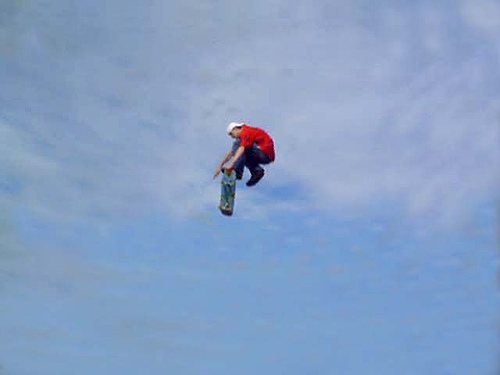

**Baixar a imagem:**

Imagem baixada com sucesso!

Imagem original:


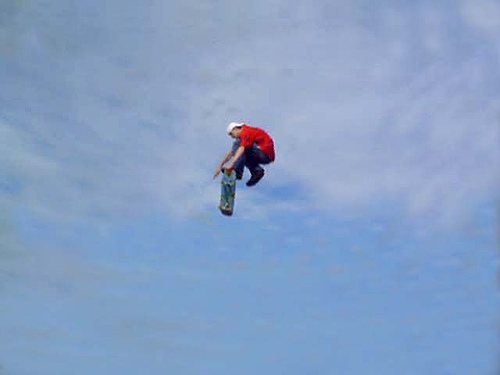


Dimensões da imagem: (375, 500, 3)


In [ ]:
url = "https://raw.githubusercontent.com/M-Eduarda-S/projeto_m2_2_filtragem_na_frequencia_morfologia_e_segmentacao/main/imagens/2012_001200.jfif"
img_path = "2012_001200.jfif"

try:
    urllib.request.urlretrieve(url, img_path)
    print("Imagem baixada com sucesso!")
except Exception as e:
    print(f"Erro ao baixar a imagem: {e}")

img_original = cv2.imread(img_path)

if img_original is not None:
    print("\nImagem original:")
    cv2_imshow(img_original)
    print("\nDimensões da imagem:", img_original.shape) # vai dar altura, largura e quantidade de canais de cor
else:
    print("Erro: não foi possível carregar a imagem.")

### 2. Adicionar ruído gaussiano ou speckle à imagem.

Simulação de degradação da imagem via ruído gaussiano (a justificativa técnica da escolha em detrimento do ruído Speckle encontra-se no relatório principal)

In [ ]:
def adicionar_ruido_gaussiano(imagem, media=0, desvio_padrao=25, seed=42):
    if seed is not None:
        np.random.seed(seed)

    ruido = np.random.normal(media, desvio_padrao, imagem.shape)
    img_float = imagem.astype(np.float32) + ruido
    img_ruidosa = np.zeros_like(img_float)

    if len(img_float.shape) == 2:  # Grayscale
        for i in range(img_float.shape[0]):
            for j in range(img_float.shape[1]):
                pixel_val = img_float[i, j]
                if pixel_val < 0:
                    img_ruidosa[i, j] = 0
                elif pixel_val > 255:
                    img_ruidosa[i, j] = 255
                else:
                    img_ruidosa[i, j] = pixel_val
    elif len(img_float.shape) == 3:  # RGB
        for i in range(img_float.shape[0]):
            for j in range(img_float.shape[1]):
                for c in range(img_float.shape[2]):
                    pixel_val = img_float[i, j, c]
                    if pixel_val < 0:
                        img_ruidosa[i, j, c] = 0
                    elif pixel_val > 255:
                        img_ruidosa[i, j, c] = 255
                    else:
                        img_ruidosa[i, j, c] = pixel_val

    return img_ruidosa.astype(np.uint8)

Imagem original: 


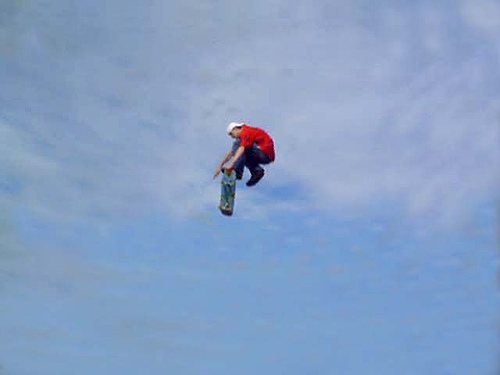


Imagem com ruído: 


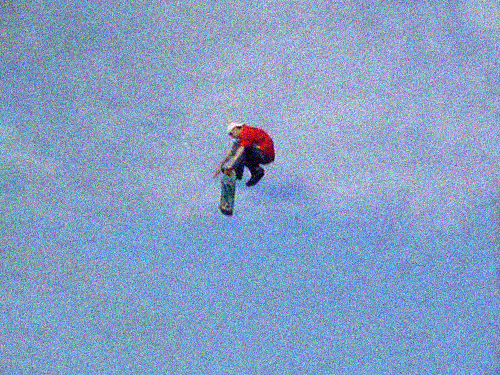

In [ ]:
img_ruido = adicionar_ruido_gaussiano(img_original)

print("Imagem original: ")
cv2_imshow(img_original)

print("\nImagem com ruído: ")
cv2_imshow(img_ruido)

### 3. Realizar filtragem no domínio da frequência (ex.: com filtro Gaussiano ou Butterworth na frequência).

- criar_mascara_filtro: Gera os filtros passa-baixa (Gaussiano e Butterworth) utilizando o cálculo de distância euclidiana a partir do centro óptico.  
- aplicar_filtro_frequencia: Executa a Transformada de Fourier (FFT), centraliza as frequências, aplica a máscara escolhida e reverte para o domínio espacial (iFFT).   
- visualizar_espectros: Exibe o espectro de magnitude logarítmica antes e depois da aplicação da máscara para validação visual.

In [ ]:
def visualizar_espectros(img_ruido, mascara, titulo_filtro):
    if len(img_ruido.shape) == 3:
        img = cv2.cvtColor(img_ruido, cv2.COLOR_BGR2GRAY)
    else:
        img = img_ruido

    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)

    magnitude_antes = (20*np.log(np.abs(fshift) + 0.00001)/255)
    magnitude_antes = np.array(magnitude_antes, dtype=np.float32)

    mascara_2d = mascara[:, :, 0] if len(mascara.shape) == 3 else mascara
    fshift_filtrado = fshift * mascara_2d

    magnitude_depois = (20*np.log(np.abs(fshift_filtrado) + 0.00001)/255)
    magnitude_depois = np.array(magnitude_depois, dtype=np.float32)

    plt.figure(figsize=(10, 5))

    plt.subplot(121), plt.imshow(magnitude_antes, cmap='gray')
    plt.title('Antes da filtragem'), plt.xticks([]), plt.yticks([])

    plt.subplot(122), plt.imshow(magnitude_depois, cmap='gray')
    plt.title(f'Depois da filtragem - {titulo_filtro}'), plt.xticks([]), plt.yticks([])

    plt.show()

In [ ]:
def aplicar_filtro_frequencia(imagem, mascara):
    F = np.fft.fft2(imagem, axes=(0, 1)) # axes=(0,1) é necessário pois a imagem é colorida
    F_shifted = np.fft.fftshift(F, axes=(0, 1))

    G_shifted = F_shifted * mascara

    G_ishifted = np.fft.ifftshift(G_shifted, axes=(0, 1))
    img_back = np.fft.ifft2(G_ishifted, axes=(0, 1))

    filtered_img = np.abs(img_back)

    filtered_img -= filtered_img.min()

    filtered_img = (filtered_img * 255) / filtered_img.max()

    filtered_img = filtered_img.astype(np.uint8)

    return filtered_img

In [ ]:
def criar_mascara_filtro(shape, tipo_filtro, cutoff_frequency, order=2):
    rows, cols = shape[:2]
    crow, ccol = rows // 2, cols // 2

    Y, X = np.ogrid[:rows, :cols]
    distance = np.sqrt((X - ccol)**2 + (Y - crow)**2)

    if tipo_filtro.lower() == 'butterworth':
        filter_kernel = 1 / (1 + (distance / (cutoff_frequency + 1e-5))**(2 * order))

    elif tipo_filtro.lower() == 'gaussiano':
        filter_kernel = np.exp(-(distance**2) / (2 * (cutoff_frequency**2)))

    if len(shape) == 3:
        filter_kernel = filter_kernel[:, :, np.newaxis]

    return filter_kernel.astype(np.float32)

#### Butterworth

In [ ]:
mascara_butterworth = criar_mascara_filtro(img_ruido.shape, 'butterworth', cutoff_frequency=45, order=2)

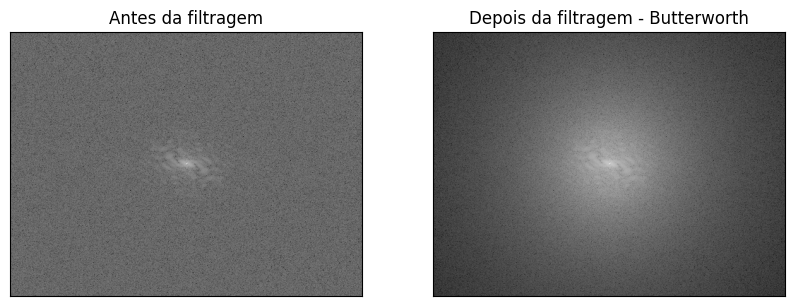

In [ ]:
visualizar_espectros(img_ruido, mascara_butterworth, "Butterworth")

Butterworth:


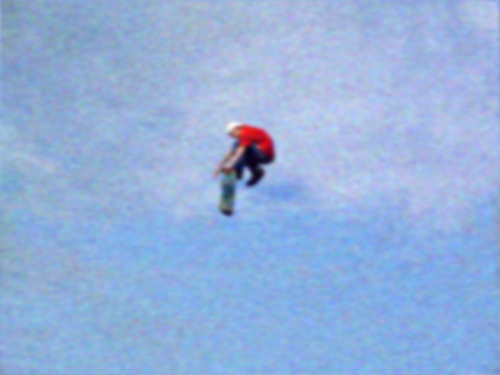

In [ ]:
img_suavizada_b = aplicar_filtro_frequencia(img_ruido, mascara_butterworth) # retorna ao dominio espacial
print("Butterworth:")
cv2_imshow(img_suavizada_b)

#### Gaussiano

Frequência de corte (D0) = 45: Valor ajustado para remover os ruídos de alta frequência do fundo sem borrar excessivamente a silhueta principal.

Ordem (n) = 2: Ordem baixa escolhida propositalmente para minimizar o efeito de anelamento (ringing), comum neste filtro quando utilizado com ordens mais altas.

Gaussiano:


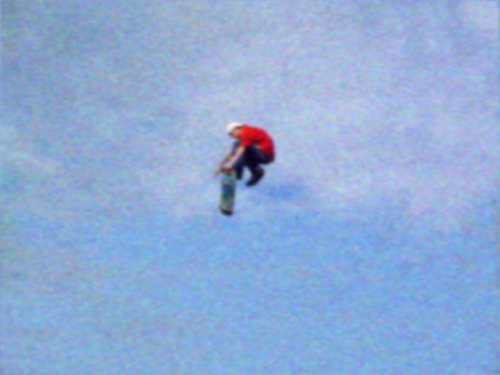

In [ ]:
mascara_gaussiana = criar_mascara_filtro(img_ruido.shape, 'gaussiano', cutoff_frequency=45)
img_suavizada_g = aplicar_filtro_frequencia(img_ruido, mascara_gaussiana)
print("Gaussiano:")
cv2_imshow(img_suavizada_g)

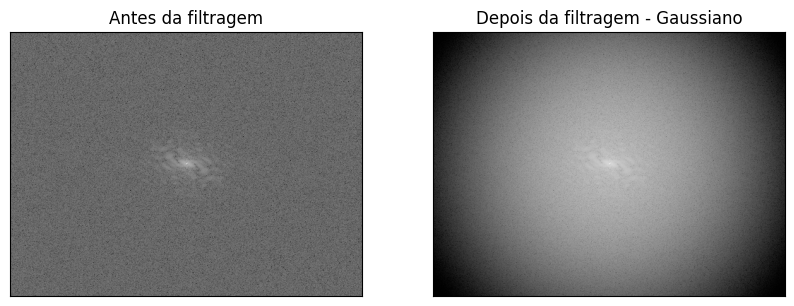

In [ ]:
visualizar_espectros(img_ruido, mascara_gaussiana, "Gaussiano")

### 4. Avaliar a qualidade da filtragem usando métricas como:

Cálculo das métricas de qualidade para quantificar:

- O impacto do ruído inicial inserido na imagem original.

- A capacidade de recuperação estrutural e redução de erro dos filtros Gaussiano e Butterworth.

(A análise crítica destes resultados encontram-se no relatório principal).

In [ ]:
def calcular_metricas(nome, img_referencia, img_comparada):
    '''
    Função que calcula as métricas PSNR e SSIM entre duas imagens e imprime o resultado
    '''
    psnr_val = peak_signal_noise_ratio(img_referencia, img_comparada, data_range=255)

    ssim_val = structural_similarity(img_referencia, img_comparada, data_range=255, channel_axis=-1) # channel_axis=-1 só é utiliziado se estiver comparando imagens coloridas, tipo BGR/RGB de 3 canais

    print(f"{nome} -> PSNR: {psnr_val:.4f} | SSIM: {ssim_val:.4f}")

In [ ]:
# Dicionário para armazenar as imagens em diferentes etapas do pipeline, organizado por nome da lesão
imagens = {
    "2012_001200": {
        "original": img_original,
        "degradada": img_ruido,
        "suavizada_butterworth": img_suavizada_b,
        "suavizada_gaussiano": img_suavizada_g
    },
}

In [ ]:
for nome_imagem, etapas in imagens.items():
    print(f"\nAnalisando a imagem {nome_imagem}:")

    # Métrica do ruído inicial
    calcular_metricas("Original x Degradada", etapas["original"], etapas["degradada"])

    # Comparação entre os filtros
    calcular_metricas("Original x Suavizada (Butterworth)", etapas["original"], etapas["suavizada_butterworth"])
    calcular_metricas("Original x Suavizada (Gaussiano)", etapas["original"], etapas["suavizada_gaussiano"])


Analisando a imagem 2012_001200:
Original x Degradada -> PSNR: 20.2128 | SSIM: 0.1107
Original x Suavizada (Butterworth) -> PSNR: 22.6683 | SSIM: 0.8296
Original x Suavizada (Gaussiano) -> PSNR: 24.9181 | SSIM: 0.7788


### 5. Aplicar segmentação com:

#### 5.1. Watershed

A aplicação do algoritmo Watershed foi estruturada em três etapas lógicas e sequenciais:
1. Cálculo do Gradiente: Geração do mapa de bordas utilizando o operador Sobel, criando a "superfície topográfica" necessária para o algoritmo.   
2. Definição de Marcadores (Sementes): Seleção manual de coordenadas (x,y) indicando as regiões seguras de fundo (bordas externas) e do objeto de interesse (skatista).   
3. Inundação Topográfica: Execução do algoritmo de crescimento de regiões a partir dos marcadores pré-definidos.

In [ ]:
# Watershed espera uma imagem gradiente -> Tópico 10.5.3 da bibliografia

def sobel_canal(gray):
    p = np.pad(gray, 1, mode='reflect')
    gx = (p[:-2, 2:] + 2*p[1:-1, 2:] + p[2:, 2:]) - (p[:-2, :-2] + 2*p[1:-1, :-2] + p[2:, :-2])
    gy = (p[2:, :-2] + 2*p[2:, 1:-1] + p[2:, 2:]) - (p[:-2, :-2] + 2*p[:-2, 1:-1] + p[:-2, 2:])
    return gx, gy

def gradiente_cores(img):
    img = img.astype(np.float32)
    soma = np.zeros(img.shape[:2], dtype=np.float32)
    for c in range(3):                      # R, G, B
        gx, gy = sobel_canal(img[:, :, c])
        soma += gx**2 + gy**2
    return np.sqrt(soma)

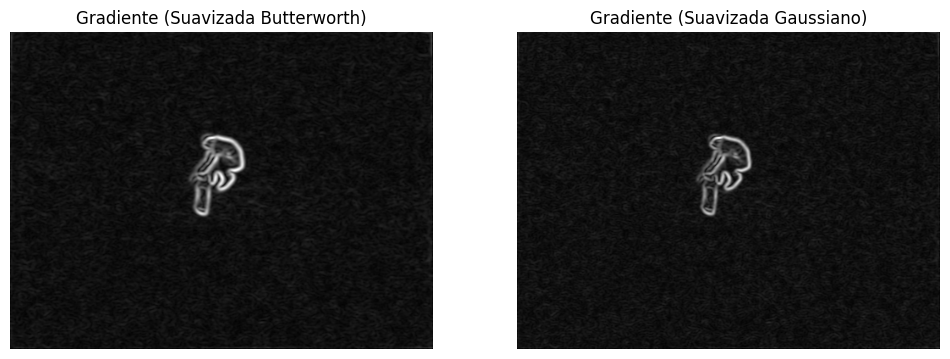

In [ ]:
grad_b = gradiente_cores(img_suavizada_b)
grad_g = gradiente_cores(img_suavizada_g)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(grad_b, cmap='gray')
plt.title('Gradiente (Suavizada Butterworth)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(grad_g, cmap='gray')
plt.title('Gradiente (Suavizada Gaussiano)')
plt.axis('off')

plt.show()

In [ ]:
def get_neighbors(i, j, h, w):
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            ni, nj = i + di, j + dj
            if 0 <= ni < h and 0 <= nj < w:
                yield ni, nj

def watershed(image, markers):
    h, w = image.shape
    labels = markers.copy()
    pq = []

    for i in range(h):
        for j in range(w):
            if labels[i, j] > 0:
                heappush(pq, (image[i, j], i, j))

    while pq:
        _, i, j = heappop(pq)
        for ni, nj in get_neighbors(i, j, h, w):
            if labels[ni, nj] == 0:
                labels[ni, nj] = labels[i, j]
                heappush(pq, (image[ni, nj], ni, nj))
            elif labels[ni, nj] != labels[i, j]:
                labels[i, j] = -1
    return labels

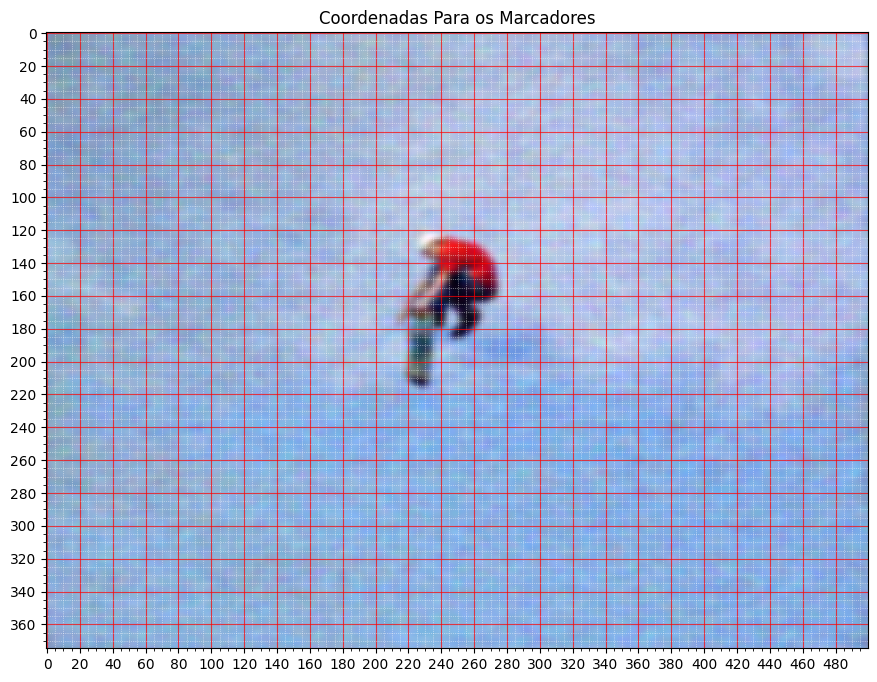

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(cv2.cvtColor(img_suavizada_b, cv2.COLOR_BGR2RGB))

ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
ax.yaxis.set_major_locator(ticker.MultipleLocator(20))
ax.grid(which='major', color='red', linestyle='-', linewidth=0.8, alpha=0.7)

ax.xaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.grid(which='minor', color='white', linestyle=':', linewidth=0.5, alpha=0.8)

plt.title("Coordenadas Para os Marcadores")
plt.show()

In [ ]:
h, w = img_suavizada_b.shape[:2]

markers = np.zeros((h, w), dtype=np.int32)

# Cria uma moldura que marca o fundo
markers[0:5, :] = 2
markers[-5:, :] = 2
markers[:, 0:5] = 2
markers[:, -5:] = 2

# Bone (y=~125, x=230)
markers[124:127, 229:232] = 1

# Rosto (y=125-130, x=~235)
markers[125:131, 234:237] = 1

# Camisa (y=135, x=260) - quadrado 5x5
markers[133:138, 258:263] = 1

# Camisa (y=160, x=250) - quadrado 5x5
markers[158:163, 248:253] = 1

# Skate (y=175-205, x=225-230)
markers[175:206, 225:231] = 1

# Braço: linha de pontos 3x3 entre ombro e mão
cv2.line(markers, (240, 145), (217, 172), 1, thickness=3)

array([[2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 2],
       ...,
       [2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 2]], shape=(375, 500), dtype=int32)

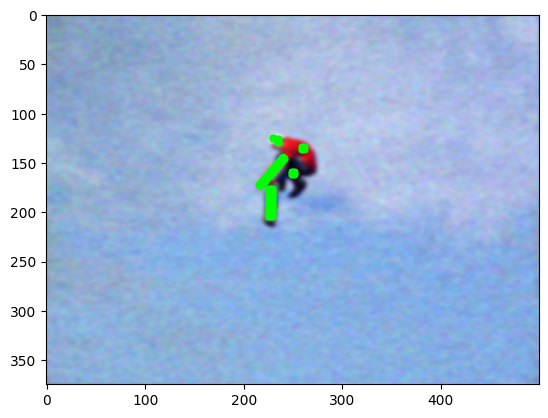

In [ ]:
plt.imshow(cv2.cvtColor(np.clip(img_suavizada_b, 0, 255).astype(np.uint8), cv2.COLOR_BGR2RGB))
ys, xs = np.where(markers == 1)
plt.scatter(xs, ys, c='lime', s=10)
plt.show()

In [ ]:
# Aplica o watershed nas duas imagens
labels_butterworth = watershed(grad_b, markers)
labels_gaussiano = watershed(grad_g, markers)

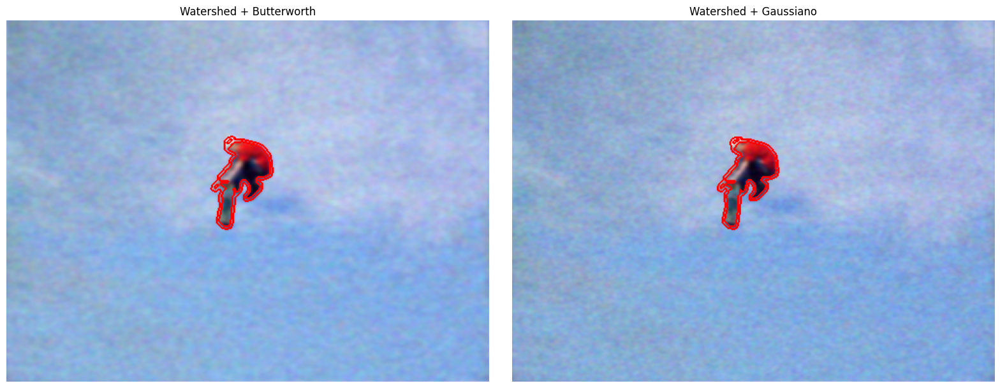

In [ ]:
img_b_rgb = cv2.cvtColor(img_suavizada_b, cv2.COLOR_BGR2RGB)
img_g_rgb = cv2.cvtColor(img_suavizada_g, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

ax[0].imshow(mark_boundaries(img_b_rgb, labels_butterworth, color=(1, 0, 0)))
ax[0].set_title('Watershed + Butterworth')
ax[0].axis('off')

ax[1].imshow(mark_boundaries(img_g_rgb, labels_gaussiano, color=(1, 0, 0)))
ax[1].set_title('Watershed + Gaussiano')
ax[1].axis('off')

plt.tight_layout()
plt.show()

#### 5.2. SLIC (Simple Linear Iterative Clustering)

A segmentação baseada em agrupamento de regiões pelo método SLIC (Simple Linear Iterative Clustering) foi executada nas seguintes etapas operacionais:

1. Conversão de Espaço de Cor: Transformação da imagem para o padrão RGB, garantindo o cálculo correto da similaridade de cores pelo algoritmo.

2. Agrupamento (Clustering): Particionamento da imagem em blocos estruturais (configurado para 200 superpixels), balanceando a proximidade espacial e a cor.

3. Demarcação de Bordas: Extração e sobreposição visual das fronteiras geradas sobre a imagem, permitindo a análise da fragmentação do skatista em relação ao plano de fundo.

In [ ]:
def initialize_clusters(image, S):
    h, w = image.shape[:2]
    clusters = []
    for y in range(S // 2, h, S):
        for x in range(S // 2, w, S):
            ic = image[y, x].astype(float)
            clusters.append([float(y), float(x), ic])
    return clusters

def compute_slic_distance(y, x, cluster, image, S, m):
    yc, xc, ic = cluster
    ds2 = (y - yc)**2 + (x - xc)**2

    pixel = image[y, x].astype(float)
    dc2 = np.sum((pixel - ic)**2)

    return np.sqrt(dc2 + ((m / S)**2) * ds2)

def slic(image, num_superpixels=100, m=10, max_iter=10):
    h, w = image.shape[:2]
    S = max(1, int(np.sqrt((h * w) / num_superpixels)))

    clusters = initialize_clusters(image, S)
    K = len(clusters)

    labels = -np.ones((h, w), dtype=np.int32)
    distances = np.full((h, w), np.inf)

    for _ in range(max_iter):
        for k, cluster in enumerate(clusters):
            yc, xc, _ = cluster
            y0, y1 = int(max(yc - S, 0)), int(min(yc + S, h))
            x0, x1 = int(max(xc - S, 0)), int(min(xc + S, w))

            for y in range(y0, y1):
                for x in range(x0, x1):
                    d = compute_slic_distance(y, x, cluster, image, S, m)
                    if d < distances[y, x]:
                        distances[y, x] = d
                        labels[y, x] = k

        new_clusters = []
        for k in range(K):
            ys, xs = np.where(labels == k)
            if len(ys) == 0:
                new_clusters.append(clusters[k])
                continue

            yc, xc = np.mean(ys), np.mean(xs)
            ic = np.mean(image[ys, xs], axis=0)
            new_clusters.append([yc, xc, ic])

        clusters = new_clusters
        distances.fill(np.inf)

    return labels

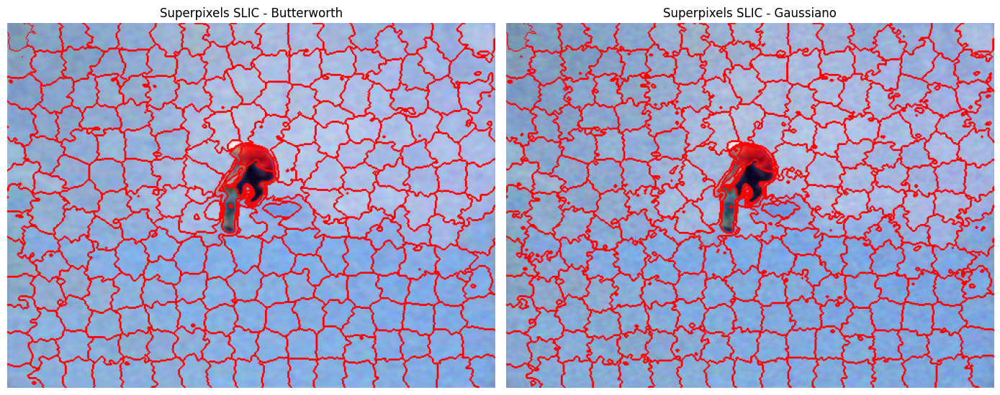

In [ ]:
img_b_rgb = cv2.cvtColor(img_suavizada_b, cv2.COLOR_BGR2RGB)
img_g_rgb = cv2.cvtColor(img_suavizada_g, cv2.COLOR_BGR2RGB)

labels_slic_b = slic(img_b_rgb, num_superpixels=210, m=20)
labels_slic_g = slic(img_g_rgb, num_superpixels=210, m=20)

imagem_com_bordas_b = mark_boundaries(img_b_rgb, labels_slic_b, color=(1, 0, 0))
imagem_com_bordas_g = mark_boundaries(img_g_rgb, labels_slic_g, color=(1, 0, 0))

fig, axs = plt.subplots(1, 2, figsize=(14, 7))

axs[0].imshow(imagem_com_bordas_b)
axs[0].set_title('Superpixels SLIC - Butterworth')
axs[0].axis('off')

axs[1].imshow(imagem_com_bordas_g)
axs[1].set_title('Superpixels SLIC - Gaussiano')
axs[1].axis('off')

plt.tight_layout()
plt.show()

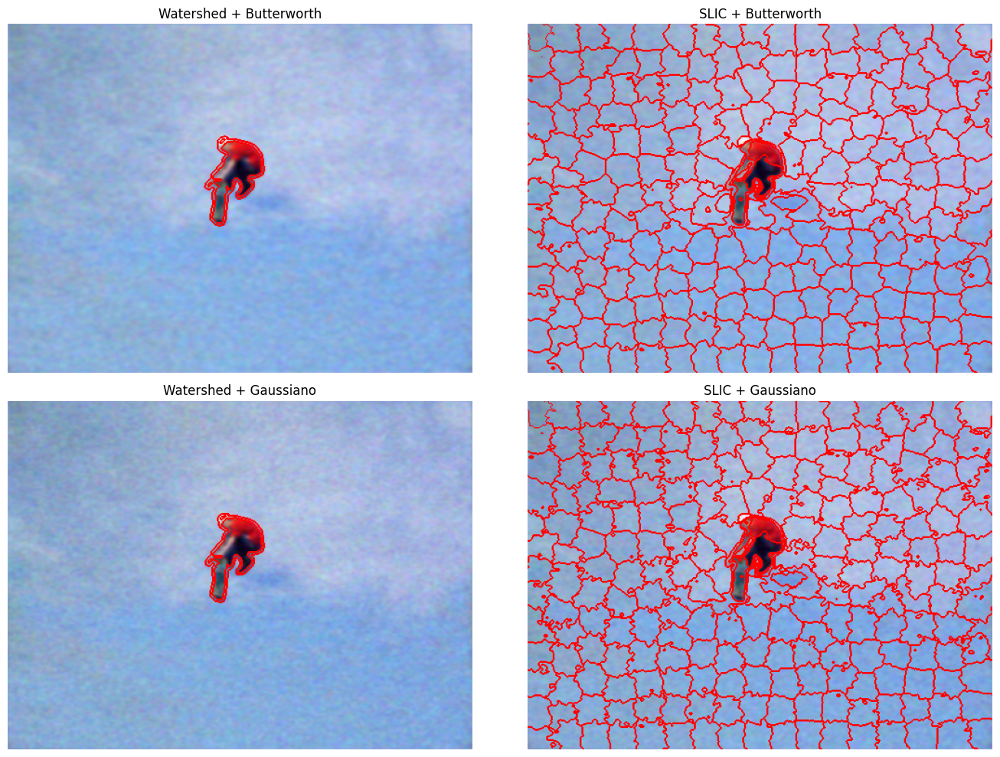

In [ ]:
img_b_rgb = cv2.cvtColor(img_suavizada_b, cv2.COLOR_BGR2RGB)
img_g_rgb = cv2.cvtColor(img_suavizada_g, cv2.COLOR_BGR2RGB)

# --- 1. Preparando as imagens do SLIC ---
imagem_slic_b = mark_boundaries(img_b_rgb, labels_slic_b, color=(1, 0, 0))
imagem_slic_g = mark_boundaries(img_g_rgb, labels_slic_g, color=(1, 0, 0))

# --- 2. Preparando as imagens do Watershed ---
imagem_watershed_b = mark_boundaries(img_b_rgb, labels_butterworth, color=(1, 0, 0))
imagem_watershed_g = mark_boundaries(img_g_rgb, labels_gaussiano, color=(1, 0, 0))

# --- 3. Criando a grade 2x2 para confronto direto ---
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# LINHA 1: Comparativo com filtro Butterworth
axs[0, 0].imshow(imagem_watershed_b)
axs[0, 0].set_title('Watershed + Butterworth')
axs[0, 0].axis('off')

axs[0, 1].imshow(imagem_slic_b)
axs[0, 1].set_title('SLIC + Butterworth')
axs[0, 1].axis('off')

# LINHA 2: Comparativo com filtro Gaussiano
axs[1, 0].imshow(imagem_watershed_g)
axs[1, 0].set_title('Watershed + Gaussiano')
axs[1, 0].axis('off')

axs[1, 1].imshow(imagem_slic_g)
axs[1, 1].set_title('SLIC + Gaussiano')
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()

### 6. Síntese Comparativa dos Resultados (Watershed vs. SLIC)


* Metodologia de Análise Visual

  * Avaliação qualitativa focada na precisão do recorte: A análise consiste em inspecionar visualmente a fidelidade das fronteiras geradas pelos algoritmos em relação à imagem original. Para o Watershed, verifica-se a precisão do isolamento da silhueta do alvo e a ocorrência de supersegmentações internas. Para o SLIC, avalia-se se os limites dos superpixels respeitaram adequadamente as transições naturais de cor e contraste do cenário e do objeto.

* Número de Regiões

  * Watershed: Segmentou a imagem focando na separação do alvo principal, resultando na região do plano de fundo e na região do skatista, com apenas pequenas subdivisões extras isolando o boné e um dos braços devido ao contraste de cores nessas extremidades.

  * SLIC: Particionou a imagem nas 210 regiões (superpixels) estipuladas por parâmetro.

* Contorno com o Original

  * Watershed: Conseguiu isolar o objeto de interesse com boa fidelidade, separando a silhueta principal em relação ao fundo. A marcação apresentou uma linha dupla no tracejado do contorno e pequenas divisões internas localizadas.

  * SLIC: Agrupou diferentes partes do objeto e do cenário estritamente de acordo com a similaridade de cores e proximidade, dividindo a silhueta do skatista em várias sub-regiões menores (superpixels).

## **Parte 2 – Segmentação Morfológica e Gap-Filling para Contagem de Células**

### Funções gerais

In [ ]:
# mostra as imagens lado a lado
def mostrar_etapas(imagens, titulos, titulo_geral, colunas=4):
    linhas = (len(imagens) + colunas - 1) // colunas
    fig, eixos = plt.subplots(linhas, colunas, figsize=(5 * colunas, 5 * linhas))
    fig.suptitle(titulo_geral)
    eixos = np.array(eixos).ravel()

    for eixo in eixos:
        eixo.axis('off')
    for eixo, imagem, titulo in zip(eixos, imagens, titulos):
        eixo.imshow(imagem, cmap='gray', vmin=0, vmax=255)
        eixo.set_title(titulo)

    plt.show()

# gera histograma
def gerar_histograma(img):

  histogram = np.zeros(256, dtype=int)

  if len(img.shape) == 3:
      img_cinza = np.zeros((img.shape[0], img.shape[1]), dtype=np.uint8)

      for i in range(img.shape[0]):
        for j in range(img.shape[1]):

          b = img[i, j, 0]
          g = img[i, j, 1]
          r = img[i, j, 2]

          valor_cinza = int(0.114 * b + 0.587 * g + 0.299 * r)

          #fique entre 0 e 255
          if valor_cinza < 0:
              valor_cinza = 0
          elif valor_cinza > 255:
              valor_cinza = 255

          img_cinza[i, j] = valor_cinza

  else:
      img_cinza = img

      #fiquem entre 0 e 255
      if img_cinza.dtype != np.uint8:
          img_cinza = img_cinza.copy()

          for i in range(img_cinza.shape[0]):
            for j in range(img_cinza.shape[1]):

              valor = img_cinza[i, j]

              if valor < 0:
                  valor = 0
              elif valor > 255:
                  valor = 255

              img_cinza[i, j] = valor

          img_cinza = img_cinza.astype(np.uint8)

  for i in range(img_cinza.shape[0]):
    for j in range(img_cinza.shape[1]):
      histogram[img_cinza[i, j]] += 1

  return histogram


# gráfico usado na questão 3 para mostrar melhor os resultados das contagens das células
def graficos_questao3(nome, conexao, buracos):
    fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
    fig.suptitle(f"{nome} - total de {sum(conexao)} células")
    b1 = eixos[0].bar(["Não conectadas", "Parcialmente\nconectadas", "Cortadas\npela borda"], conexao, color=["green", "gold", "orange"])
    eixos[0].bar_label(b1)
    eixos[0].set_title("Conexão entre as células")
    b2 = eixos[1].bar(["Com buraco\ninterno", "Sem buraco\ninterno", "Não\nidentificado"], buracos, color=["blue", "red", "brown"])
    eixos[1].bar_label(b2)
    eixos[1].set_title("Buracos internos")
    plt.tight_layout()
    plt.show()

### 1. Pré-processamento

#### Ler a imagem em tons de cinza

Primeira imagem baixada com sucesso!
Segunda imagem baixada com sucesso!

Primeira imagem:


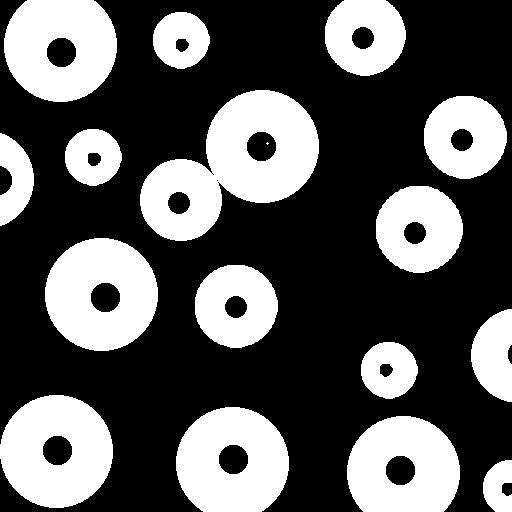

Dimensões da primeira imagem: (512, 512)

Segunda imagem:


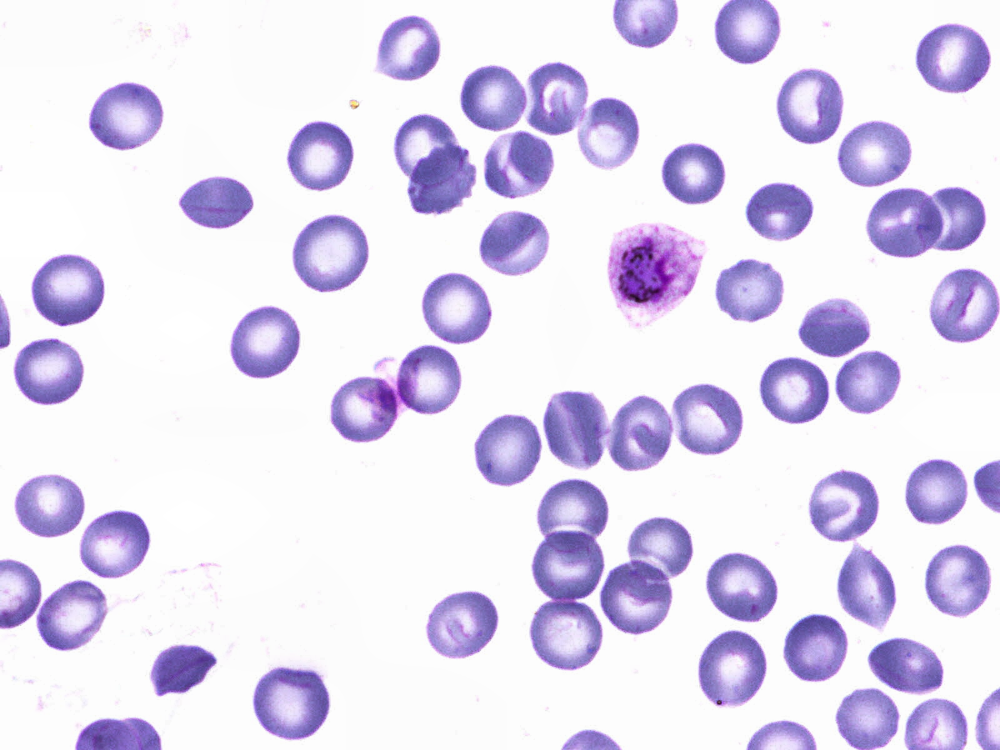

Dimensões da segunda imagem: (1200, 1600, 3)

Segunda imagem com as dimensões reduzidas:


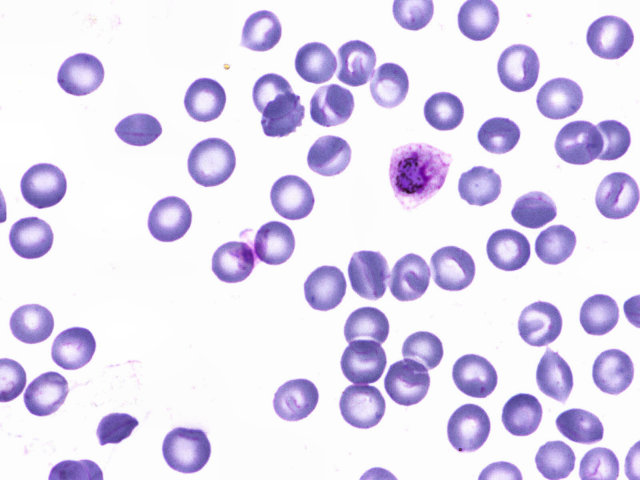

Dimensões da segunda imagem com as dimensões reduzidas: (480, 640, 3)

Segunda imagem em tons de cinza:


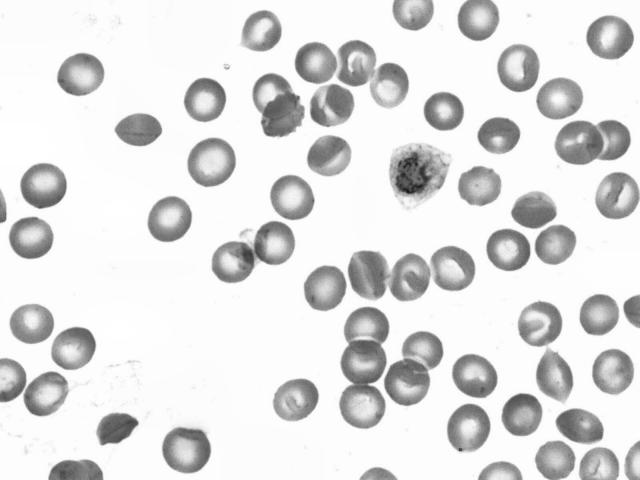

Dimensões da segunda imagem em tons de cinza: (480, 640)


In [ ]:
url2 = "https://raw.githubusercontent.com/M-Eduarda-S/projeto_m2_2_filtragem_na_frequencia_morfologia_e_segmentacao/main/imagens/gap-region-filling.tif"
url3 = "https://raw.githubusercontent.com/M-Eduarda-S/projeto_m2_2_filtragem_na_frequencia_morfologia_e_segmentacao/main/imagens/002f20ad-2ace-499c-9335-c9080bc3e6b5.png"

img2_path = "gap-region-filling.tif"
img3_path = "002f20ad-2ace-499c-9335-c9080bc3e6b5.png"

try:
    urllib.request.urlretrieve(url2, img2_path)
    print("Primeira imagem baixada com sucesso!")

    urllib.request.urlretrieve(url3, img3_path)
    print("Segunda imagem baixada com sucesso!")

except Exception as e:
    print(f"Erro ao baixar as imagens: {e}")

# primeria imagem
img1 = cv2.imread(img2_path, 0)

if img1 is not None:
    print("\nPrimeira imagem:")
    cv2_imshow(img1)
    print("Dimensões da primeira imagem:", img1.shape)

else:
    print("Erro: não foi possível carregar a primeira imagem.")

# segunda imagem
img2_original = cv2.imread(img3_path) # img2 colorida só para mostrar como ela era
img2_cinza = cv2.imread(img3_path, 0) # img2 em cinza que vai ser usada no trabalho

if img2_original is not None:
    print("\nSegunda imagem:")
    cv2_imshow(img2_original)
    print("Dimensões da segunda imagem:", img2_original.shape)

    print("\nSegunda imagem com as dimensões reduzidas:")
    img2_reduzida = cv2.resize(img2_original, None, fx=0.40, fy=0.40, interpolation=cv2.INTER_AREA) # img2 colorida e reduzida (só para mostrar como fica)
    cv2_imshow(img2_reduzida)
    print("Dimensões da segunda imagem com as dimensões reduzidas:", img2_reduzida.shape)

    print("\nSegunda imagem em tons de cinza:")
    img2 = cv2.resize(img2_cinza, None, fx=0.40, fy=0.40, interpolation=cv2.INTER_AREA) #vai ser usada nas próximas etapas (mg2 cinza e reduzida)
    cv2_imshow(img2)

    print("Dimensões da segunda imagem em tons de cinza:", img2.shape)

else:
    print("Erro: não foi possível carregar a segunda imagem.")

Reduzimos a segunda imagem para **40% do tamanho original**, porque as funções de morfologia que usamos percorrem a imagem com vários laços e na imagem inteira demorariam muito.

#### Resposta da escolha de aplicar filtro Gaussiano leve (opcional) para reduzir ruído ou não.

**Não aplicamos** o filtro Gaussiano porque ele é **opcional** e, neste trabalho, o ruído que sobra depois da limiarização (pontinhos brancos soltos e buracos pequenos) já é **tratado nas operações morfológicas da questão 4**, com o fechamento, o preenchimento de buracos e a abertura.

Além disso, o filtro borra as bordas das células, o que pode ajudar a juntar células que estão encostadas.



### 2. Limiarização

A limiarização transforma a imagem em cinza em uma imagem binária. Os pixels acima do limiar viram 255 (branco) e os outros viram 0 (preto). Comparamos dois métodos (Otsu e Global simples) e o Otsu foi o escolhido.

- Otsu (método escolhido): olha o histograma da imagem e escolhe sozinho o limiar que melhor separa os pixels em dois grupos, os claros e os escuros. Não precisa de nenhum parâmetro.
- Global simples (usado só para comparar): começa com a média da imagem como limiar e vai ajustando até ele parar de mudar. Precisa de um valor de parada, o delta T.

#### Funções utilizadas

Funções:

- otsu_threshold: calcula o limiar de Otsu.
- aplicar_otsu: aplica um limiar na imagem (acima vira 255 e o resto vira 0). Usamos ela também com o limiar do global simples.
- limiar_global_simples: calcula o limiar global simples a partir do histograma. Devolve o limiar final e o valor do limiar em cada iteração.
- comparar_metodos: aplica os dois métodos na mesma imagem. Devolve os limiares, as duas imagens e quantos pixels ficaram diferentes.
- plotar_histograma_limiares: mostra o histograma com uma linha em cada limiar.

In [ ]:
# Função Otsu calcula o limiar de Otsu pela maior variância entre as classes
def otsu_threshold(image):
    image = image.astype(np.uint8)
    hist = np.bincount(image.ravel(), minlength=256) # quantos pixels há em cada nível de cinza
    prob = hist / image.size

    cumulative_prob = np.cumsum(prob)
    cumulative_mean = np.cumsum(prob * np.arange(256))
    global_mean = cumulative_mean[-1]

    numerator = (global_mean * cumulative_prob - cumulative_mean) ** 2
    denominator = cumulative_prob * (1 - cumulative_prob)
    denominator = np.where(denominator == 0, 1e-10, denominator)

    sigma_b2 = numerator / denominator

    return int(np.argmax(sigma_b2))


def aplicar_otsu(image, threshold):
    return (image > threshold).astype(np.uint8) * 255


# Função de limiar global simples, baseada nas etapas mostrado no slide da disciplina
def limiar_global_simples(histograma, delta_T=0.5):
    # calcula a média da imagem usando o histograma
    total_pixels = 0
    soma_niveis = 0

    for nivel in range(256):
        total_pixels += histograma[nivel] # quantos pixels têm esse nível
        soma_niveis += nivel * histograma[nivel]

    T = soma_niveis / total_pixels  # o limiar inicial é a média da imagem (a própria função escolhe)
    historico = [T]

    while True:
        qtd_g1, soma_g1 = 0, 0 # pixels acima de T
        qtd_g2, soma_g2 = 0, 0 # pixels iguais ou abaixo de T

        # separação dos níveis de cinza nos dois grupos
        for nivel in range(256):
            if nivel > T:
                qtd_g1 += histograma[nivel]
                soma_g1 += nivel * histograma[nivel] # soma quantos pixels e quanto valor tem em cada um
            else:
                qtd_g2 += histograma[nivel]
                soma_g2 += nivel * histograma[nivel]

        if qtd_g1 == 0 or qtd_g2 == 0:
            break  # se grupo ficou vazio, não dá para calcular a média dele

        novo_T = (soma_g1 / qtd_g1 + soma_g2 / qtd_g2) / 2 # média das médias dos dois grupos
        historico.append(novo_T)

        diferenca = abs(novo_T - T) # quando o T muda menos que o delta T
        T = novo_T

        if diferenca < delta_T:
            break

    return T, historico


#aplica Otsu e o Global simples na mesma imagem e compara os resultados
def comparar_metodos(img, histograma, inverter=False, delta_T=0.5):
    # calcula os dois limiares
    limiar_otsu = otsu_threshold(img)
    limiar_global, historico_T = limiar_global_simples(histograma, delta_T)

    # aplica cada limiar (acima do limiar vira 255 e o resto vira 0)
    img_otsu = aplicar_otsu(img, limiar_otsu)
    img_global = aplicar_otsu(img, limiar_global)

    # na img2 as células são escuras, então inverte para as células ficarem brancas
    if inverter:
        img_otsu = 255 - img_otsu
        img_global = 255 - img_global

    # pixels que as duas imagens tem de diferentes
    pixels_diferentes = 0
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            if img_otsu[i, j] != img_global[i, j]:
                pixels_diferentes += 1

    return {"limiar_otsu": limiar_otsu, "limiar_global": limiar_global, "historico_T": historico_T, "img_otsu": img_otsu, "img_global": img_global, "pixels_diferentes": pixels_diferentes}


# Mostra o histograma com uma linha vertical para cada limiar
def plotar_histograma_limiares(histograma, limiares, titulo, escala_log=True):
    # ajustes
    x = np.linspace(0, 255, 256)
    cores = ['red', 'blue', 'green']
    estilos = ['--', ':', '-.']

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(x, histograma, width=1.0, color='gray')

    # linha vertical para cada limiar recebido (nome e valor)
    for (nome, valor), cor, estilo in zip(limiares.items(), cores, estilos):
        ax.axvline(valor, color=cor, linestyle=estilo, label=f'{nome} ({valor:.1f})')

    # escala log ajuda quando um pico (o fundo) é muito maior que o resto
    if escala_log:
        ax.set_yscale('log')
        ax.set_ylabel('frequência (escala log)')
    else:
        ax.set_ylabel('frequência')

    ax.set_title(titulo)
    ax.set_xlabel('intensidade')
    ax.legend()

    plt.tight_layout()
    plt.show()

    return fig

#### Aplicar limiarização global ou Otsu para segmentar o foreground (núcleos).

Fizemos aqui:

- Geramos o histograma das duas imagens, aplicamos o Otsu (resultado usado nas próximas etapas) e aplicamos também o global simples para comparar.

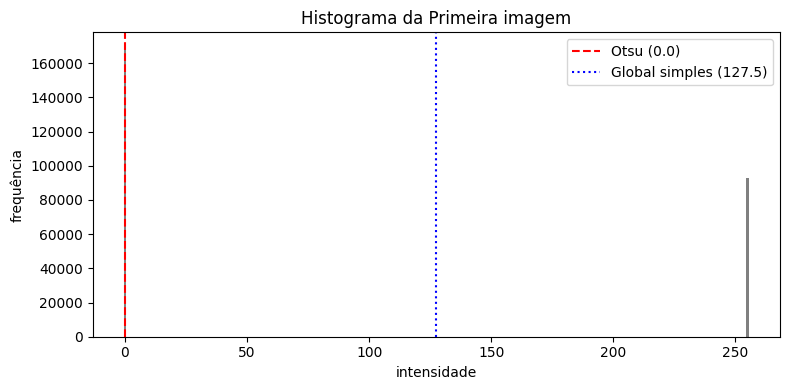

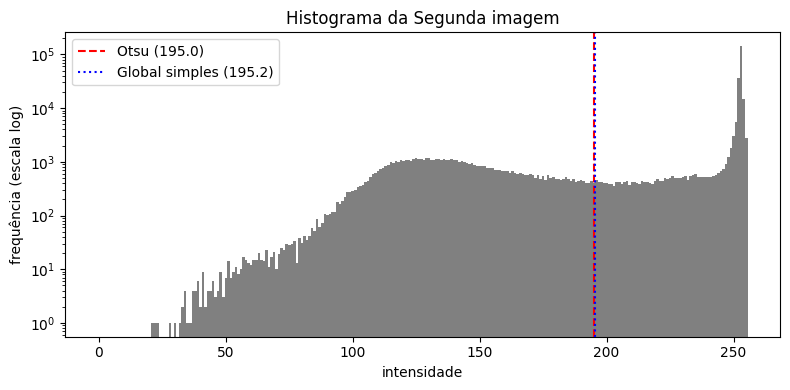

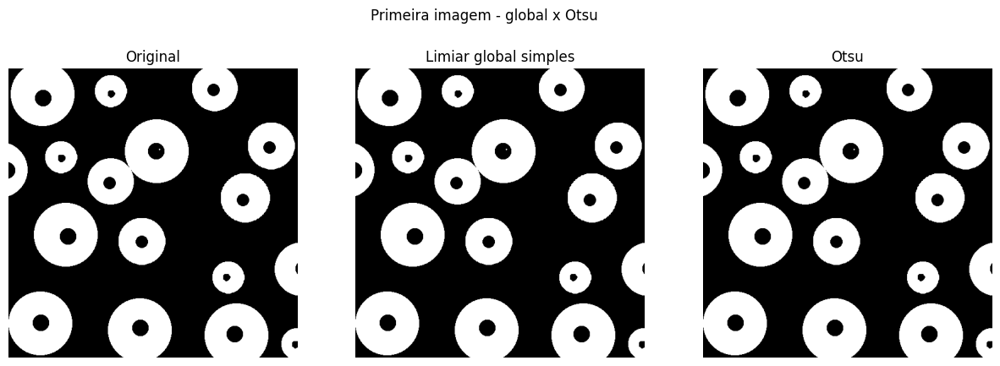

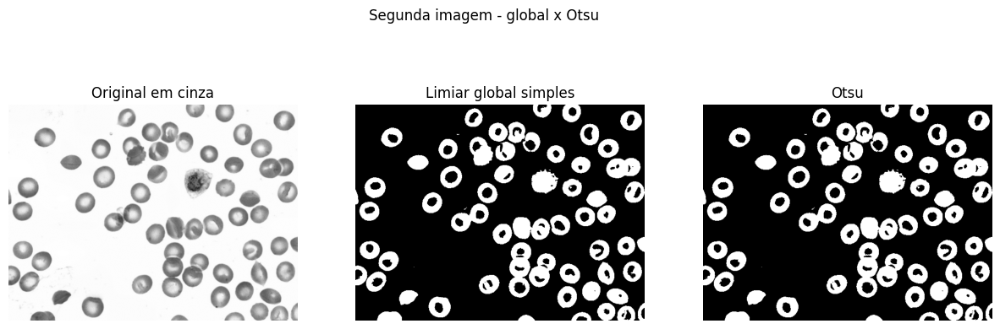


Primeira imagem - com global simples [T inicial 90.06, delta T 0.5, 2 iterações, T final 127.50]
Primeira imagem - com Otsu [limiar 0]
Primeira imagem tem 0 pixels diferentes entre os dois métodos

Segunda imagem - com global simples [T inicial 223.39, delta T 0.5, 4 iterações, T final 195.24]
Segunda imagem - com Otsu [limiar 195]
Segunda imagem tem 0 pixels diferentes entre os dois métodos



In [ ]:
delta_T = 0.5 # o algoritmo (global simples) para quando o limiar muda menos que isso

# histogramas das imagens em cinza, antes de limiarizar
hist_img1 = gerar_histograma(img1)
hist_img2 = gerar_histograma(img2)

# aplica o Otsu e o global simples em cada imagem
resultado_img1 = comparar_metodos(img1, hist_img1, delta_T=delta_T)  #img1 os objetos já são brancos
resultado_img2 = comparar_metodos(img2, hist_img2, inverter=True, delta_T=delta_T) #img2 as células são escuras por isso invertemos

# imagens binárias do Otsu usadas nas próximas etapas
img1_limiarizada = resultado_img1["img_otsu"]
img2_limiarizada = resultado_img2["img_otsu"]

# histogramas com uma linha em cada limiar
fig1 = plotar_histograma_limiares(hist_img1, {"Otsu": resultado_img1["limiar_otsu"], "Global simples": resultado_img1["limiar_global"]}, "Histograma da Primeira imagem", escala_log=False) # escala_log=False, pois ela só tem duas barras (0 e 255) e a escala log deixa o gráfico estranho
print()
fig2 = plotar_histograma_limiares(hist_img2, {"Otsu": resultado_img2["limiar_otsu"], "Global simples": resultado_img2["limiar_global"]}, "Histograma da Segunda imagem")

print()
mostrar_etapas([img1, resultado_img1["img_global"], resultado_img1["img_otsu"]], ["Original", "Limiar global simples", "Otsu"], "Primeira imagem - global x Otsu", colunas=3)
print()
mostrar_etapas([img2, resultado_img2["img_global"], resultado_img2["img_otsu"]], ["Original em cinza", "Limiar global simples", "Otsu"], "Segunda imagem - global x Otsu", colunas=3)

# valores de cada método
print()
for nome, resultado in [("Primeira imagem", resultado_img1), ("Segunda imagem", resultado_img2)]:
    historico = resultado["historico_T"]   # lista com o T de cada iteração (o primeiro é o limiar inicial)
    print(f"{nome} - com global simples [T inicial {historico[0]:.2f}, delta T {delta_T}, {len(historico) - 1} iterações, T final {resultado['limiar_global']:.2f}]")
    print(f"{nome} - com Otsu [limiar {resultado['limiar_otsu']}]")
    print(f"{nome} tem {resultado['pixels_diferentes']} pixels diferentes entre os dois métodos\n")

Testes do delta T na img2, para a escolha do valor dele:

In [ ]:
for delta in [0.01, 0.1, 0.5, 1, 5, 10]:
    T, historico = limiar_global_simples(hist_img2, delta) # roda o global simples com cada delta T

    # compara com o resultado do Otsu e conta os pixels diferentes
    diferentes = np.count_nonzero(aplicar_otsu(img2, T) != aplicar_otsu(img2, resultado_img2["limiar_otsu"]))
    print(f"delta T {delta} | limiar final {T:.2f} | {len(historico) - 1} iterações | {diferentes} pixels diferentes do Otsu")

delta T 0.01 | limiar final 195.24 | 5 iterações | 0 pixels diferentes do Otsu
delta T 0.1 | limiar final 195.24 | 5 iterações | 0 pixels diferentes do Otsu
delta T 0.5 | limiar final 195.24 | 4 iterações | 0 pixels diferentes do Otsu
delta T 1 | limiar final 195.24 | 4 iterações | 0 pixels diferentes do Otsu
delta T 5 | limiar final 196.46 | 2 iterações | 468 pixels diferentes do Otsu
delta T 10 | limiar final 196.46 | 2 iterações | 468 pixels diferentes do Otsu


Delta T (usado no global simples):
- É o quanto o limiar pode mudar de uma iteração para a outra antes do algoritmo parar.
- O slide da disciplina não define o valor, então testamos 0,01, 0,1, 0,5, 1, 5 e 10.
- Até 1 o resultado foi o mesmo (limiar final 195,24 e imagem igual à do Otsu). - Com 5 e 10 ele parou cedo demais (196,46) e 468 pixels ficaram diferentes.
- Então usamos 0,5, que dá o mesmo resultado com poucas iterações.
O limiar inicial é a média da imagem (90,06 e 223,39), calculada pela própria função.

Confirmação que a primeira imagem não mudou:

In [ ]:
# histogramas depois de limiarizar (só têm 0 e 255)
hist_img1_depois = gerar_histograma(img1_limiarizada)
hist_img2_depois = gerar_histograma(img2_limiarizada)

# quantos pixels pretos e brancos sobraram depois do Otsu
for nome, h in [("Primeira imagem", hist_img1_depois), ("Segunda imagem", hist_img2_depois)]:
    print(f"{nome} depois do Otsu tem {h[0]} pixels pretos e {h[255]} pixels brancos ({100 * h[255] / (h[0] + h[255]):.1f}% da imagem)")

# confirma que a primeira imagem não foi modificada (ela já era binária)
print("Primeira imagem igual depois do Otsu?", np.array_equal(img1, img1_limiarizada))

Primeira imagem depois do Otsu tem 169563 pixels pretos e 92581 pixels brancos (35.3% da imagem)
Segunda imagem depois do Otsu tem 233091 pixels pretos e 74109 pixels brancos (24.1% da imagem)
Primeira imagem igual depois do Otsu? True


#### Resultado: imagem binária com regiões de interesse.

Sobre os resultados observados:

Primeira imagem:
- Ela só tem os valores 0 e 255, então a limiarização não muda nada nela. O Otsu deu limiar 0, porque com só dois valores qualquer limiar entre 0 e 254 separa igual e ele fica com o primeiro.

Segunda imagem:
- O histograma tem um pico alto de pixels claros perto de 250, que é o fundo, e um grupo mais espalhado de pixels escuros, que são as células. O Otsu deu limiar 195, que fica na região entre os dois grupos, onde há menos pixels.

<br><br>

Comparação com o global simples:
- Os dois métodos deram a mesma imagem nas duas imagens (0 pixels diferentes). - O global deu 127,5 na primeira (2 iterações) e 195,24 na segunda (4 iterações).
- Na primeira, qualquer limiar entre 0 e 254 separa igual.
- Na segunda, nenhum pixel tem nível entre 195 e 195,24.

<br><br>

Por que escolhemos usar o Otsu:
- Ele deu o mesmo resultado e é mais simples.
- Calcula o limiar de uma vez e não precisa de limiar inicial nem de delta T.



Primeira imagem limiarizada com Otsu:


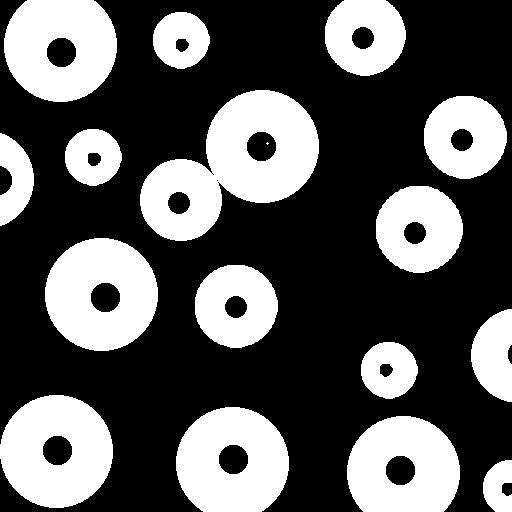


Segunda imagem limiarizada com Otsu:


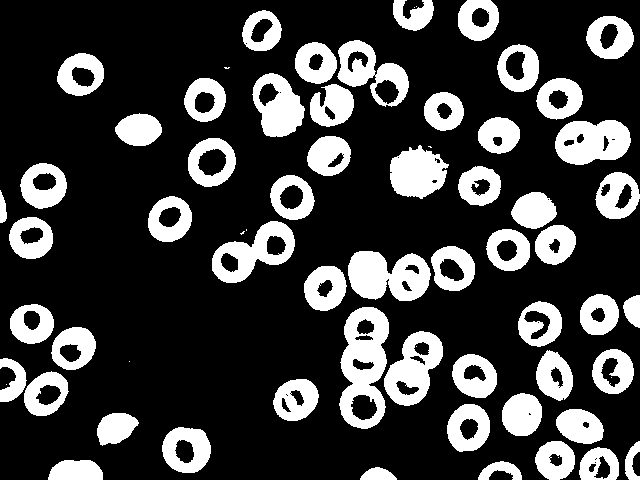

In [ ]:
print("\nPrimeira imagem limiarizada com Otsu:")
cv2_imshow(img1_limiarizada)

print("\nSegunda imagem limiarizada com Otsu:")
cv2_imshow(img2_limiarizada)

### 3. Análise das falhas

Para facilitar a análise de falhas, **classificamos** e **contabilizamos** manualmente as células da primeira e segunda imagem de acordo com as categorias abaixo:

<br>

#### Classificação das células na Primeira imagem

**Primeira imagem (Img1) - Classificamos com as células como:**

- Não conectadas (borda verde)
- Parcialmente conectadas (borda amarela)
- Cortadas pelas bordas da imagem (borda laranja)

| Img1 original |
| :---: |
| 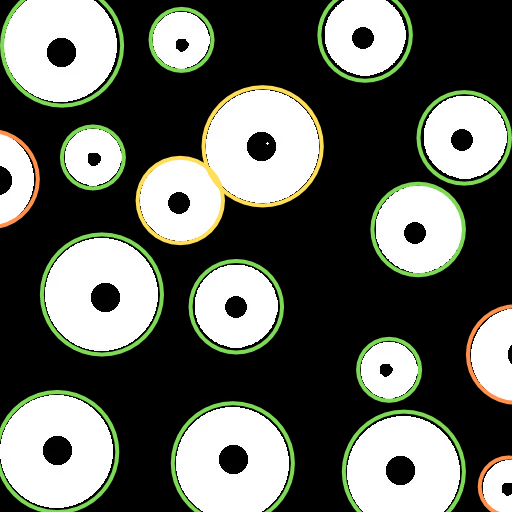 |

**Primeira imagem (Img1) - Classificamos com as células como:**

- Com buracos internos (borda azul)
- Sem buracos internos (borda vermelha)
- E as que não conseguirmos indetificar se possui algum buraco interno, pois elas estavam muito cortadas pelas bordas da imagem (borda marrom)

| Img1 original |
| :---: |
| 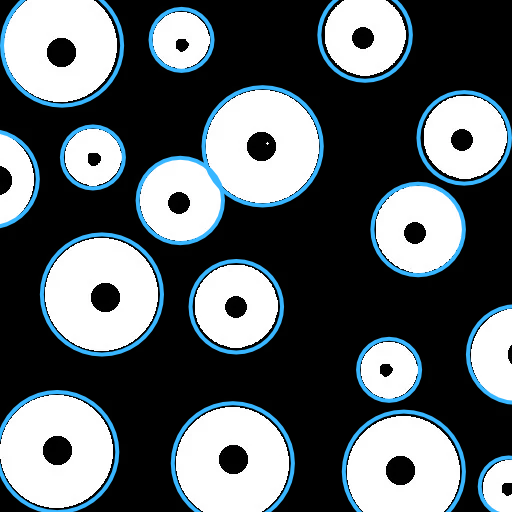 |

#### Classificação das células na Segunda imagem

**Segunda imagem (Img2) - Classificamos com as células como:**

- Não conectadas (borda verde)
- Parcialmente conectadas (borda amarela)
- Cortadas pelas bordas da imagem (borda laranja)

| Img2 original | Img2 cinza | Img2 limiarizada |
| :---: | :---: | :---: |
| 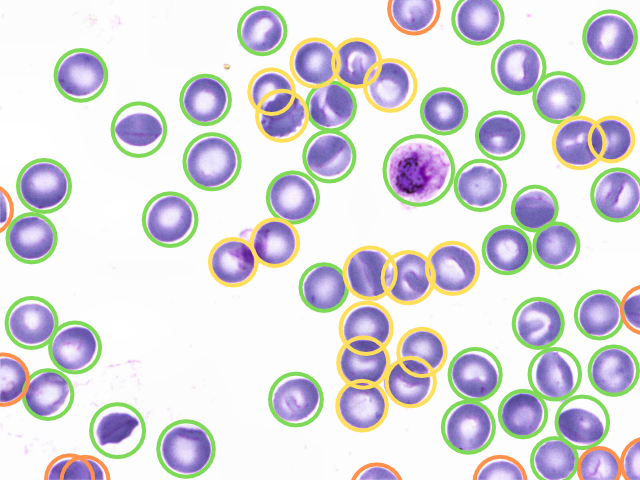 | 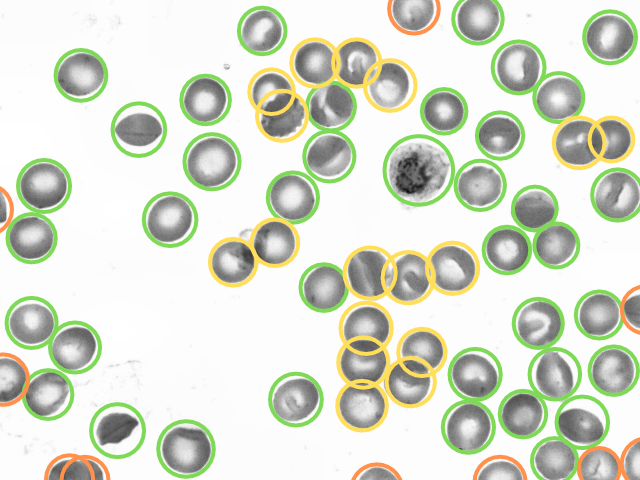 | 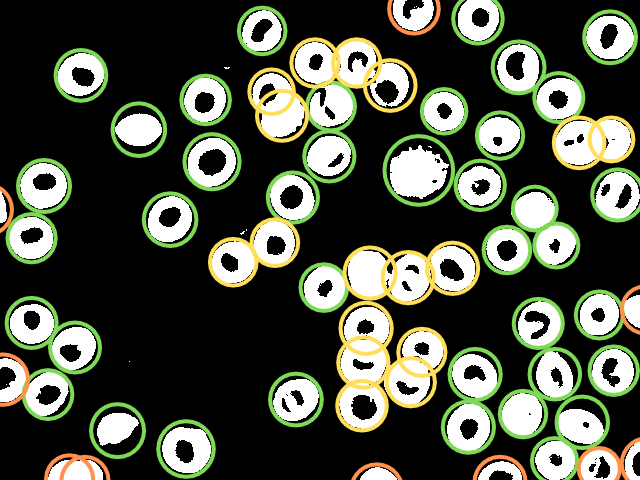 |

**Segunda imagem (Img2) - Classificamos com as células como:**

- Com buracos internos (borda azul)
- Sem buracos internos (borda vermelha)
- E as que não conseguirmos indetificar se possui algum buraco interno, pois elas estavam muito cortadas pelas bordas da imagem (borda marrom)

| Img2 original | Img2 cinza | Img2 limiarizada |
| :---: | :---: | :---: |
| 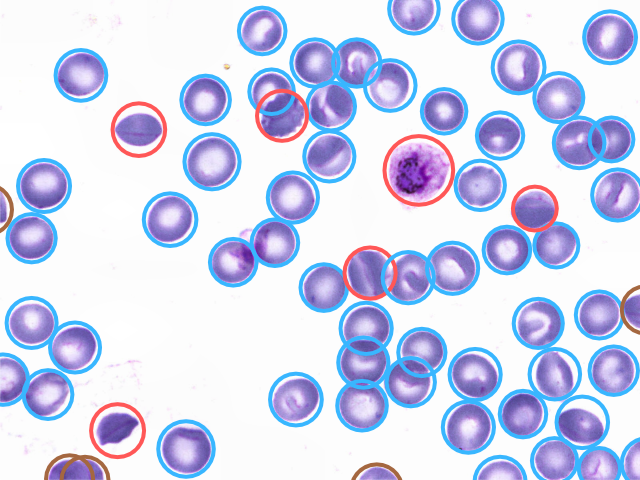 | 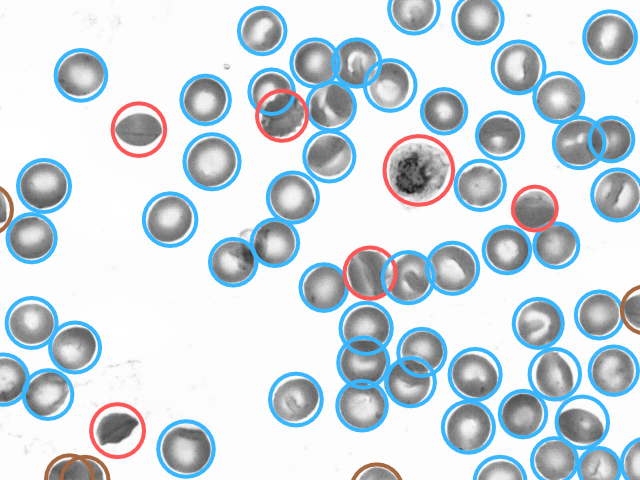 | 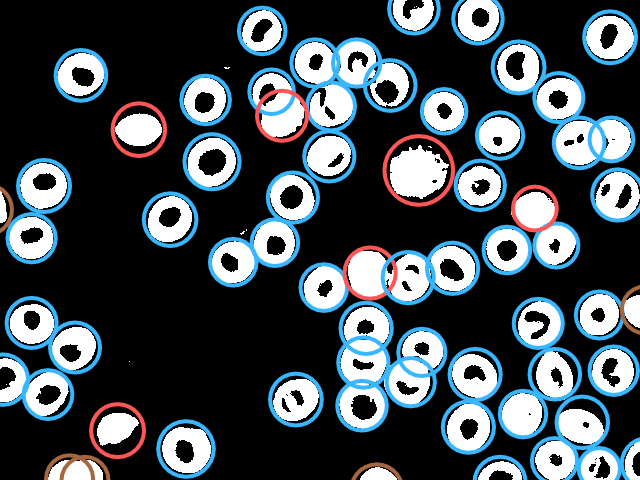 |

**Observação:** Uma célula na parte direita inferior da "Img2 limiarizada", fechou o buraco observado nas outras imagens (ainda permanece alguns pequenos pixels no centro se der zoom). Consideramos essa célula tendo classificação de "buraco interno", pois conseguimos observar ele nas outras imagens.

#### Resultados da contagem

**Primeira imagem (img1) <- Total: 17 células**
- Células não conectadas: **12**
- Células parcialmente conectadas: **2**
- Células cortadas pelas bordas da imagem: **3**
- Células com buracos internos: **17**
- Células sem buracos internos: **0**
- Células sem identificação de buracos internos (não conseguimos concluir): **0**

<br>

**Segunda imagem (img2) <- Total: 66 células**
- Células não conectadas: **39**
- Células parcialmente conectadas: **17**
- Células cortadas pelas bordas da imagem: **10**
- Células com buracos internos: **55**
- Células sem buracos internos: **6**
- Células sem identificação de buracos internos (não conseguimos concluir): **5**

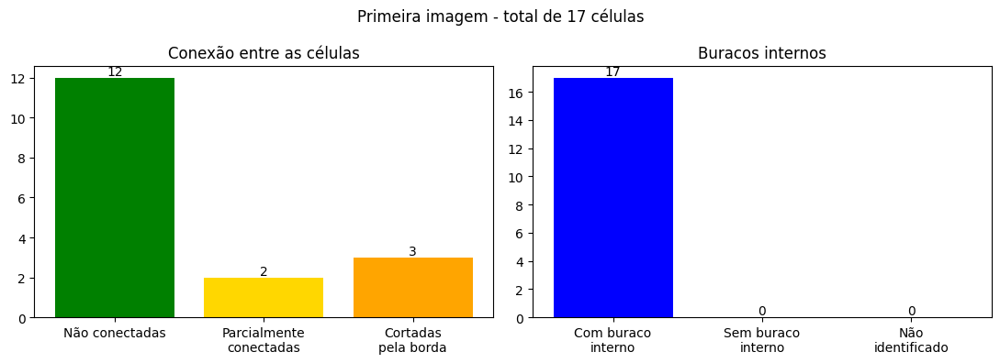

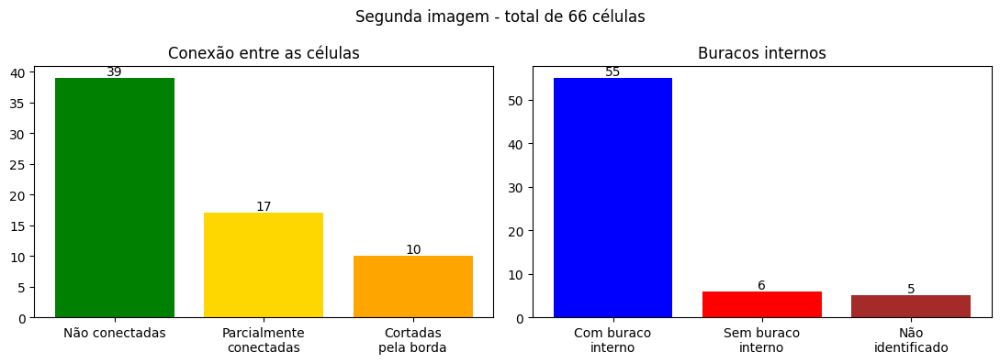

In [ ]:
graficos_questao3("Primeira imagem", [12, 2, 3], [17, 0, 0])
graficos_questao3("Segunda imagem", [39, 17, 10], [55, 6, 5])

### 4. Operações morfológicas

#### Funções utilizadas

Principais funções utilizadas:

- criar_elemento_circular: cria o elemento circular do raio escolhido.
- morf_dilate_erode: dilatação e erosão (função do professor). Só mudamos o padding, que passou a ser 0 na dilatação e 255 na erosão, para a erosão não apagar as células cortadas pela borda.
- preencher_buracos: preenche os buracos internos das células por meio de dilatações sucessivas do fundo.
- preencher_buracos_da_borda: trata os buracos das células cortadas pelas bordas da imagem. Para isso, espelha a imagem, realiza o preenchimento dos buracos e remove a margem adicionada, retornando a imagem ao tamanho original.

In [ ]:
def add_padding(img, padding_height, padding_width, valor=0):
    n, m = img.shape

    padded_img = np.full((n + padding_height * 2, m + padding_width * 2), valor)
    padded_img[padding_height : n + padding_height, padding_width : m + padding_width] = img

    return padded_img

def morf_dilate_erode(img, kernel, padding=True, dilate=True):
    k_height, k_width = kernel.shape # pega as dimensões do kernel
    img_height, img_width = img.shape # pega as dimensões da imagem

    # calcula o padding pedido
    pad_height = k_height // 2
    pad_width = k_width // 2

    # cria uma versão do padding da imagem com tratamento de bordas
    if padding == True:
      padded_img = add_padding(img, pad_height, pad_width, valor=0 if dilate else 255)

    output = np.zeros((img_height, img_width), dtype=float) # inicia a imagem de saida com zeros

    if dilate == True: # Analisa se há algum hit entre elemento e janela
      print("Operação de Dilatação")

      for i_img in range(img_height):
         for j_img in range(img_width):
               match_element = 0

               for i_kernel in range(k_height):
                  for j_kernel in range(k_width):
                           if (kernel[i_kernel, j_kernel] == 255):
                              if(padded_img[i_img+i_kernel, j_img+j_kernel] == kernel[i_kernel, j_kernel]):
                                 match_element = 1
               if(match_element == 1):
                  output[i_img, j_img] = 255
               else:
                  output[i_img, j_img] = 0
    else:
      print("Operação de Erosão")

      for i_img in range(img_height):
         for j_img in range(img_width):
               match_element = 1
               for i_kernel in range(k_height):
                  for j_kernel in range(k_width):
                           if (kernel[i_kernel, j_kernel] == 255):
                              if(padded_img[i_img+i_kernel, j_img+j_kernel] != kernel[i_kernel, j_kernel]):  # analisa se não há algum hit entre elemento e janela
                                 match_element = 0
               if(match_element == 0):
                  output[i_img, j_img] = 0
               else:
                  output[i_img, j_img] = 255

    return np.array(output, dtype=np.uint8)


# cria o elemento estruturante circular
def criar_elemento_circular(raio):
    tam = 2 * raio + 1 # tamanho do lado da matriz
    elemento = np.zeros((tam, tam), dtype=np.uint8)

    for i in range(tam):
        for j in range(tam):
            # se a distância do pixel até o centro da matriz for menor ou igual ao raio, o pixel está dentro do círculo
            if (i - raio) ** 2 + (j - raio) ** 2 <= raio ** 2:
                elemento[i, j] = 255
    return elemento


# preenche os buracos pretos que ficam dentro das células
def preencher_buracos(img, elemento_preenchimento):
    complemento = (img == 0) # True nos pixels pretos (fundo e buracos)

    # marcador inicial, os pixels pretos das bordas da imagem (com certeza são fundo)
    marcador = np.zeros_like(complemento)
    marcador[0, :] = complemento[0, :]
    marcador[-1, :] = complemento[-1, :]
    marcador[:, 0] = complemento[:, 0]
    marcador[:, -1] = complemento[:, -1]

    # posição central do elemento estruturante
    centro_y = elemento_preenchimento.shape[0] // 2
    centro_x = elemento_preenchimento.shape[1] // 2

    pontos = np.argwhere(elemento_preenchimento == 255) # coordenadas dos pixels ativos do elemento
    passadas = 0

    while True:
        dilatado = np.zeros_like(marcador)

        # dilatação, desloca o marcador na direção de cada pixel ativo do elemento e junta tudo
        for ky, kx in pontos:
            desloc_y = ky - centro_y
            desloc_x = kx - centro_x

            # recorta a origem (onde o marcador está) e o destino (para onde ele vai) para caber dentro da imagem
            origem_y = max(0, -desloc_y)
            origem_y_fim = min(img.shape[0], img.shape[0] - desloc_y)

            origem_x = max(0, -desloc_x)
            origem_x_fim = min(img.shape[1], img.shape[1] - desloc_x)

            destino_y = max(0, desloc_y)
            destino_y_fim = min(img.shape[0], img.shape[0] + desloc_y)

            destino_x = max(0, desloc_x)
            destino_x_fim = min(img.shape[1], img.shape[1] + desloc_x)

            dilatado[destino_y:destino_y_fim, destino_x:destino_x_fim] |= marcador[origem_y:origem_y_fim, origem_x:origem_x_fim]

        novo = dilatado & complemento # o fundo só cresce nos pixels que eram pretos na imagem original
        passadas += 1

        if np.array_equal(novo, marcador): # o fundo parou de crescer
            break

        marcador = novo

    resultado = np.where(marcador, 0, 255).astype(np.uint8)  # o que o fundo não alcançou vira branco

    return resultado, passadas - 1, passadas

# espelha a imagem e chama a função que preenche os buracos
def preencher_buracos_da_borda(img, margem=20, elemento_preenchimento=None):
    if elemento_preenchimento is None:
        elemento_preenchimento = criar_elemento_circular(1) # mais seguro para o preenchimento (raio 1)

    espelhada = np.pad(img, margem, mode='symmetric') # espelha a imagem ficando com a célula completa
    preenchida, dilatacoes, chamadas = preencher_buracos(espelhada, elemento_preenchimento) # com o buraco fechado o preenchimento normal funciona
    resultado = preenchida[margem:-margem, margem:-margem] # corta a margem e volta ao tamanho original

    return resultado, dilatacoes, chamadas


# exibe em texto o elemento circular do raio escolhido
def imprimir_elemento_circular(raio):
    elemento = criar_elemento_circular(raio)

    print(f"Elemento circular de raio {raio}, matriz {elemento.shape[0]}x{elemento.shape[1]}")
    for linha in elemento:
        print(" ".join("1" if valor == 255 else "0" for valor in linha))

    return elemento


# mostra o elemento ciruuclar de cada raio
def plotar_elementos_circulares(raios):
    fig, eixos = plt.subplots(1, len(raios), figsize=(4 * len(raios), 4))
    eixos = np.array(eixos).ravel()

    for eixo, raio in zip(eixos, raios):
        elemento = criar_elemento_circular(raio)
        tam = elemento.shape[0]

        eixo.imshow(elemento, cmap='gray', vmin=0, vmax=255)

        # linhas cinzas entre os pixels para a matriz ficar visível
        eixo.set_xticks(np.arange(-0.5, tam, 1), minor=True)
        eixo.set_yticks(np.arange(-0.5, tam, 1), minor=True)
        eixo.grid(which='minor', color='gray', linewidth=1)
        eixo.set_xticks([])
        eixo.set_yticks([])
        eixo.set_title(f"Raio {raio} ({tam}x{tam})")

    plt.tight_layout()
    plt.show()

    return fig

# para mostrar o espelhamento das margens testadas
def mostrar_teste_espelhamento(img, margem_testada, elemento_preenchimento, nome_imagem):
    espelhada = np.pad(img, margem_testada, mode='symmetric') # faz o espelhamento da imagem

    espelhada_preenchida, _, _ = preencher_buracos(espelhada, elemento_preenchimento) # chama a função de preenchimento dos buracos na imagem espelhada
    resultado, _, _ = preencher_buracos_da_borda(img, margem_testada, elemento_preenchimento) #remove a margem e retorna ao tamanho da imagem

    altura, largura = img.shape
    imagens = [espelhada, espelhada_preenchida, resultado]
    titulos = [f"1) Imagem espelhada com {margem_testada} pixels","2) Preenchimento de buracos na imagem espelhada","3) Margem cortada, volta ao tamanho original"]

    fig, eixos = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"Espelhamento nas bordas da {nome_imagem}",y=1.02)

    for k, (eixo, imagem, titulo) in enumerate(zip(eixos, imagens, titulos)):
        eixo.imshow(imagem, cmap='gray', vmin=0, vmax=255)
        eixo.set_title(titulo)
        eixo.axis('off')

        # O retângulo vermelho marca a imagem original
        if k < 2:
            eixo.add_patch(Rectangle((margem_testada - 0.5, margem_testada - 0.5),largura,altura,fill=False,edgecolor='red',linewidth=2))

    plt.tight_layout()
    plt.show()

# compara cada margem com uma margem muito grande (só para referência de uma imagem que esteja com todos os buracos preenchidos)
def mostrar_comparacao_margens(img, margens, elemento_preenchimento, nome_imagem, margem_referencia=200):
    referencia, _, _ = preencher_buracos_da_borda(img, margem_referencia, elemento_preenchimento) # resultado da referência

    fig, eixos = plt.subplots(1, len(margens), figsize=(5 * len(margens), 5))
    fig.suptitle(f"{nome_imagem} com margens comparadas com a margem de {margem_referencia} pixels (vermelho = diferente)", y=1.02)

    diferencas = []
    for eixo, margem in zip(eixos, margens):
        resultado, _, _ = preencher_buracos_da_borda(img, margem, elemento)   # resultado com a margem testada
        diferente = (resultado != referencia)                                 # True onde ficou diferente da referência

        # imagem colorida, com o branco e o preto do resultado e vermelho onde ficou diferente
        colorida = np.dstack([resultado, resultado, resultado])
        colorida[diferente] = [255, 0, 0]

        eixo.imshow(colorida)
        eixo.set_title(f"Margem de {margem} pixels e {np.count_nonzero(diferente)} pixels diferentes")
        eixo.axis('off')
        diferencas.append(int(np.count_nonzero(diferente)))

    plt.tight_layout()
    plt.show()
    return diferencas

#### Etapas:

In [ ]:
# valores usadas na questão 4

#raios testados
raios_fechamento = [1, 2, 3, 4, 5, 6, 7] # no fechamento
raios_abertura = [1, 2, 3, 4, 5, 6, 7] # na abertura

#raios escolhidos
r_fechamento_img1, r_fechamento_img2 = 1, 2 # no fechamento
r_abertura_img1, r_abertura_img2 = 2, 3 # na abertura

margem_espelho = 20 # faixa usada nas bordas

Elemento circular de raio 1, matriz 3x3
0 1 0
1 1 1
0 1 0
Elemento circular de raio 2, matriz 5x5
0 0 1 0 0
0 1 1 1 0
1 1 1 1 1
0 1 1 1 0
0 0 1 0 0


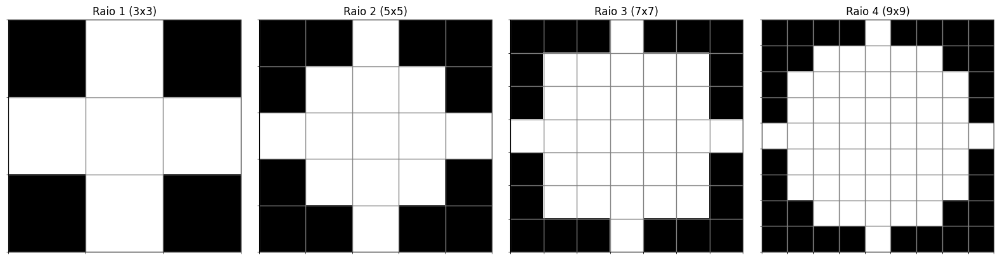

In [ ]:
# para mostrar como é o elemento circular
elemento_1 = imprimir_elemento_circular(1)
elemento_2 = imprimir_elemento_circular(2)
fig_elementos = plotar_elementos_circulares([1, 2, 3, 4])

Explicação sobre Elemento estruturante circular criado:

- É uma matriz pequena que percorre a imagem e marca quais vizinhos de cada pixel são olhados.
- O professor passou a função create_element, que faz um quadrado. Alteramos para um círculo, porque as células são redondas e o círculo trata todas as direções do mesmo jeito. O raio define o tamanho da matriz (2 x raio + 1).
- Os pixels dentro do círculo valem 255 e os cantos valem 0. Os raios 1 e 2 ficam assim (1 representa o 255).
- O raio só muda o tamanho do círculo, ele não muda quantas vezes a operação é aplicada.

##### Fechamento morfológico para conectar fragmentos.

O fechamento é uma dilatação seguida de uma erosão com o mesmo elemento.
- A dilatação cobre pequenos buracos e frestas
- A erosão devolve o tamanho dos objetos

Serve para ligar pedaços quebrados dos contornos das células.

Mostrando que a Primeira imagem está binarizada:  [  0 255]
Mostrando que a Segunda imagem está binarizada:  [  0 255]

Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão



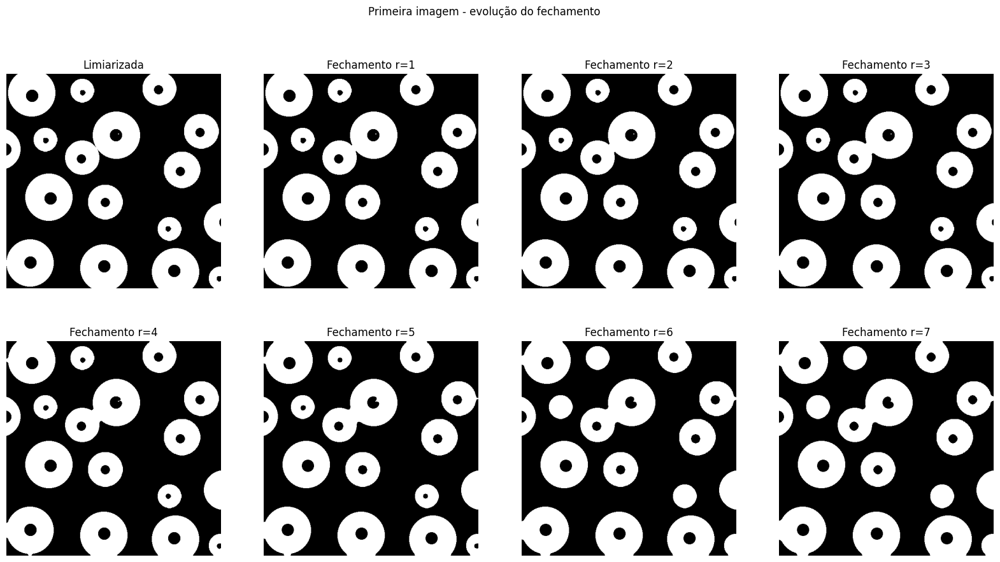

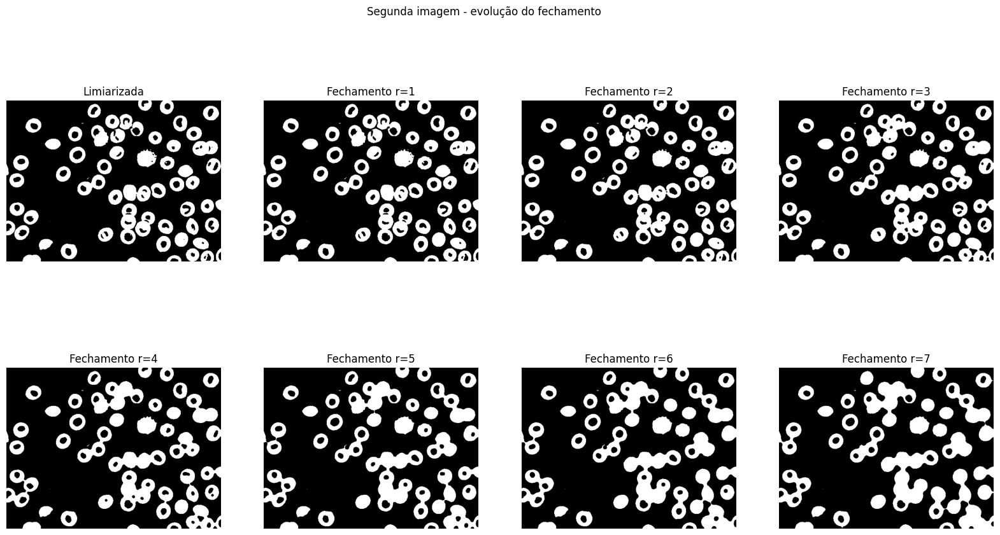


Primeira imagem com fechamento testado com os raios [1, 2, 3, 4, 5, 6, 7], cada raio com 1 dilatação e 1 erosão (14 operações)
Segunda imagem com fechamento testado com os raios [1, 2, 3, 4, 5, 6, 7], cada raio com 1 dilatação e 1 erosão (14 operações)


In [ ]:
print("Mostrando que a Primeira imagem está binarizada: ", np.unique(img1_limiarizada))
print("Mostrando que a Segunda imagem está binarizada: ", np.unique(img2_limiarizada))

# fechamento, testando raios diferentes
fechadas_img1 = {}
fechadas_img2 = {}

print()

for r in raios_fechamento:
    elemento = criar_elemento_circular(r)

    dilatada_img1 = morf_dilate_erode(img1_limiarizada, elemento, padding=True, dilate=True) # dilatação
    dilatada_img2 = morf_dilate_erode(img2_limiarizada, elemento, padding=True, dilate=True)

    fechadas_img1[r] = morf_dilate_erode(dilatada_img1, elemento, padding=True, dilate=False) # erosão (dilatação + erosão = fechamento)
    fechadas_img2[r] = morf_dilate_erode(dilatada_img2, elemento, padding=True, dilate=False)

print()

mostrar_etapas([img1_limiarizada] + [fechadas_img1[r] for r in raios_fechamento], ["Limiarizada"] + [f"Fechamento r={r}" for r in raios_fechamento], "Primeira imagem - evolução do fechamento")
print()
mostrar_etapas([img2_limiarizada] + [fechadas_img2[r] for r in raios_fechamento], ["Limiarizada"] + [f"Fechamento r={r}" for r in raios_fechamento], "Segunda imagem - evolução do fechamento")

print()
for nome in ["Primeira imagem", "Segunda imagem"]:
    print(f"{nome} com fechamento testado com os raios {raios_fechamento}, cada raio com 1 dilatação e 1 erosão ({2 * len(raios_fechamento)} operações)")

img1_fechada = fechadas_img1[r_fechamento_img1] # antes do gap-filling
img2_fechada = fechadas_img2[r_fechamento_img2]

- Raios testados: de 1 a 7 nas duas imagens, cada um com 1 dilatação e 1 erosão (14 operações por imagem).

- Raios escolhidos: 1 na primeira imagem (elemento 3x3) e 2 na segunda (elemento 5x5). O raio é o tamanho do círculo e não o número de vezes. Em cada imagem o fechamento foi aplicado uma vez só (1 dilatação e 1 erosão).

<br>

Por que esses raios:

- Primeira imagem: não tem fragmentos para ligar, e o raio 1 já bastava. Raios maiores só fecham os buraquinhos das células menores (a partir do 5 ou do 6), o que o preenchimento já faz de qualquer jeito.
- Segunda imagem: o raio 1 deixa mais anéis abertos. O raio 2 fecha mais sem juntar células vizinhas. A partir do raio 3 células vizinhas começam a se juntar, e do 5 ao 7 formam blocos grandes. Mesmo com o raio 7 os buracos grandes das células não fecham, por isso precisamos do preenchimento de buracos.

##### Preenchimento de buracos (gap-filling)

O preenchimento de buracos consiste em pintar de branco os buracos pretos que ficam dentro das células.

- O fechamento não resolve, porque só fecha buracos menores que o elemento, e os buracos das células são grandes. Nem o raio 7 fecha os maiores.

<br>

A função preencher_buracos usa morfologia e funciona olhando o fundo.

1. Começa com os pixels pretos das bordas da imagem, que com certeza são fundo.
2. Dilata esses pixels várias vezes com o elemento circular de raio 1, uma cruz 3x3 que só alcança os vizinhos de cima, de baixo, da esquerda e da direita.
3. Depois de cada dilatação, mantém só os pixels que eram pretos na imagem original. Assim o fundo se espalha sem passar por cima das células.
4. Repete até o fundo parar de crescer. O que ele não alcançou está cercado por célula, então é buraco e vira branco.

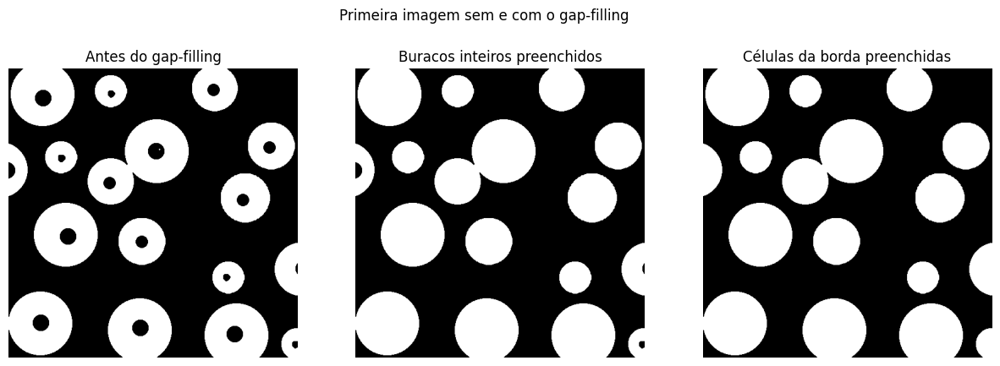

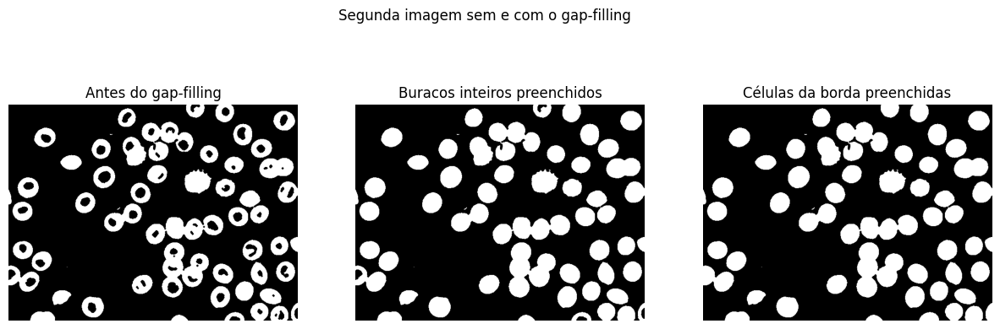


Dilatações efetivas na Primeira imagem para preencher os buracos: 287 (total de chamadas: 288)
Dilatações efetivas na Segunda imagem para preencher os buracos: 308 (total de chamadas: 309)

Dilatações efetivas na Primeira imagem para preencher os buracos nas bordas: 307 (total de chamadas: 308)
Dilatações efetivas na Segunda imagem para preencher os buracos nas bordas: 328 (total de chamadas: 329)


In [ ]:
# gap-filling
elemento_preenchimento = criar_elemento_circular(1)

img1_preenchida, dilatacoes1, chamadas1 = preencher_buracos(img1_fechada, elemento_preenchimento)
img2_preenchida, dilatacoes2, chamadas2 = preencher_buracos(img2_fechada, elemento_preenchimento)


img1_preenchida_borda, dilatacoes1_borda, chamadas1_borda = preencher_buracos_da_borda(img1_preenchida, margem_espelho, elemento_preenchimento)
img2_preenchida_borda, dilatacoes2_borda, chamadas2_borda = preencher_buracos_da_borda(img2_preenchida, margem_espelho, elemento_preenchimento)


mostrar_etapas([img1_fechada, img1_preenchida, img1_preenchida_borda],["Antes do gap-filling", "Buracos inteiros preenchidos", "Células da borda preenchidas"], "Primeira imagem sem e com o gap-filling", colunas=3)
print()
mostrar_etapas([img2_fechada, img2_preenchida, img2_preenchida_borda], ["Antes do gap-filling", "Buracos inteiros preenchidos", "Células da borda preenchidas"],"Segunda imagem sem e com o gap-filling", colunas=3)

print(f"\nDilatações efetivas na Primeira imagem para preencher os buracos: {dilatacoes1} (total de chamadas: {chamadas1})")
print(f"Dilatações efetivas na Segunda imagem para preencher os buracos: {dilatacoes2} (total de chamadas: {chamadas2})\n")

print(f"Dilatações efetivas na Primeira imagem para preencher os buracos nas bordas: {dilatacoes1_borda} (total de chamadas: {chamadas1_borda})")
print(f"Dilatações efetivas na Segunda imagem para preencher os buracos nas bordas: {dilatacoes2_borda} (total de chamadas: {chamadas2_borda})")

Quantidade de dilatações:
- Cada dilatação avança 1 pixel, então o número de dilatações é a distância, andando só pelo fundo, até o pixel de fundo mais longe da borda.
- Foram 287 na primeira imagem e 308 na segunda.
- A rodada seguinte (288 e 309 no total) só confere que o fundo parou de crescer.

Por que só dilatação:
- O fundo só precisa crescer.
- O que segura o crescimento é o corte para os pixels pretos originais, e por isso só os buracos mudam.

###### Explicação de como o espelhamento para preencher os buracos internos das células das bordas da imagem funciona

Nas células cortadas pela borda (espelhamento):
O buraco encosta na lateral e o fundo entra por ali. Então o preenchimento acha que o buraco também é fundo.
1. A função preencher_buracos_da_borda espelha a imagem nas quatro bordas.
2.  A parte cortada da célula ganha o reflexo dela do outro lado, a célula fica completa e o buraco fica fechado.
3. Depois aplica o preenchimento e corta a margem.

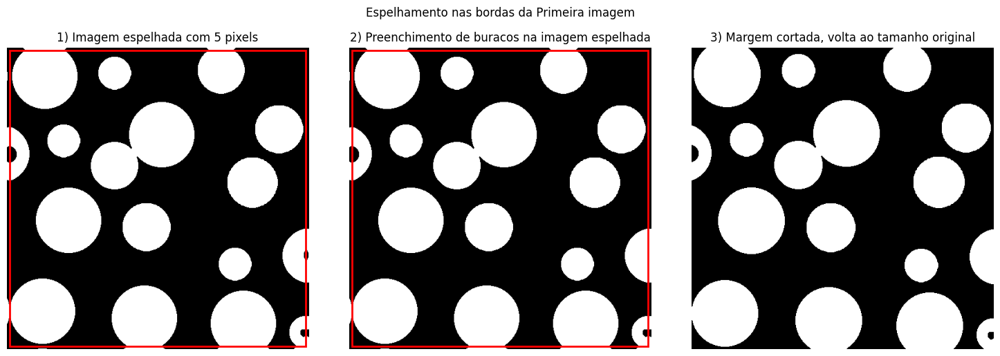

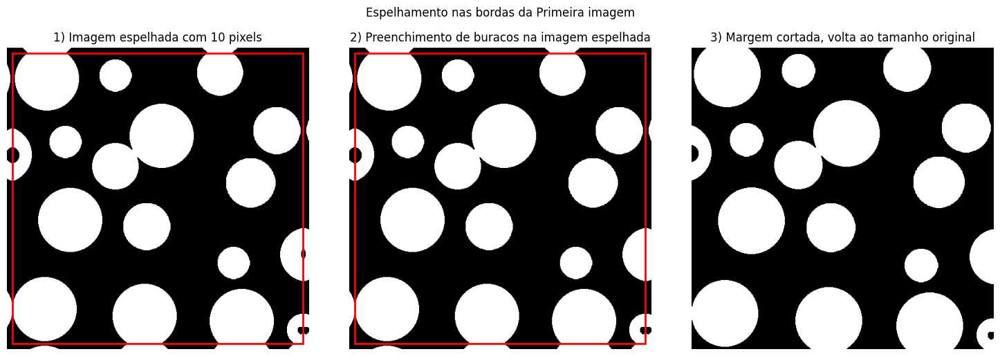

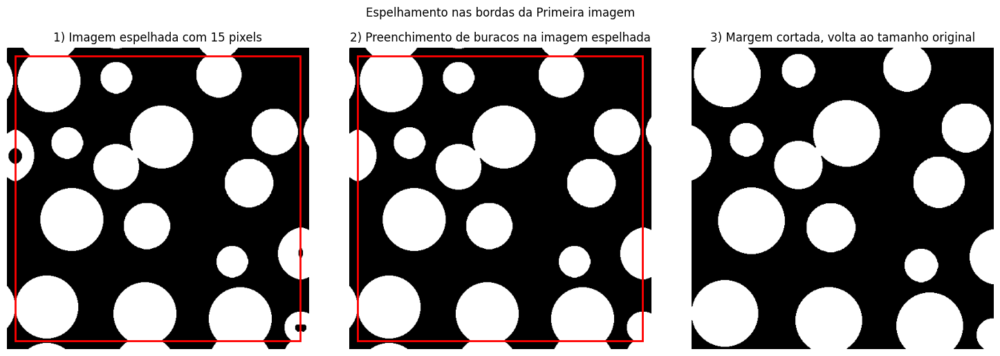

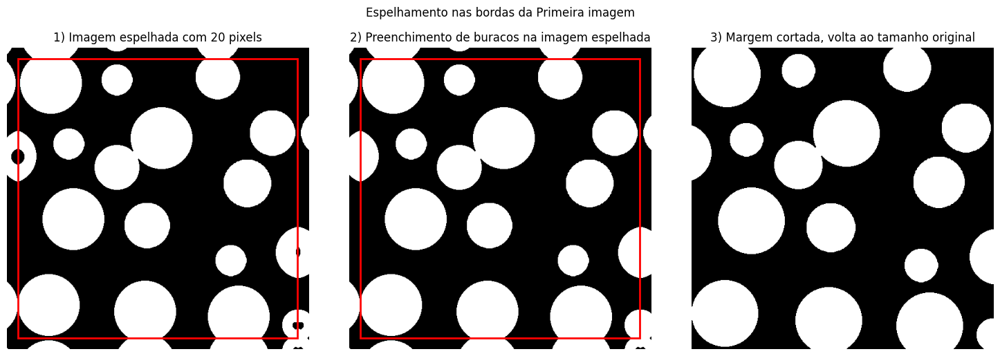

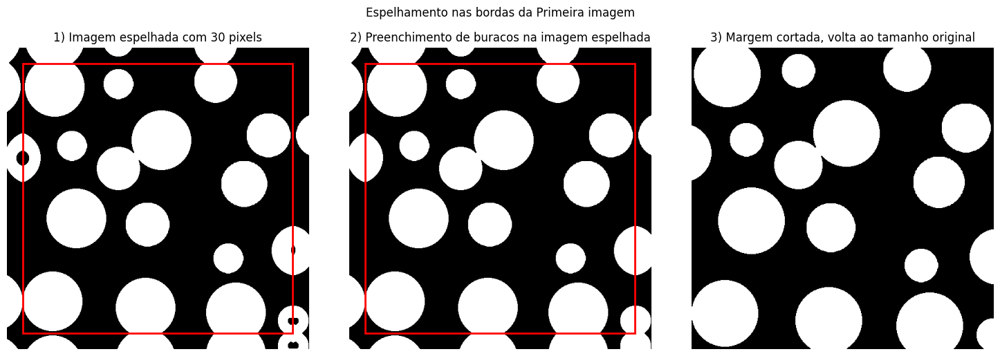

In [ ]:
# testes das margens
for margem_testada in [5, 10, 15, 20, 30]:
        mostrar_teste_espelhamento(img1_preenchida, margem_testada, elemento_preenchimento, "Primeira imagem")


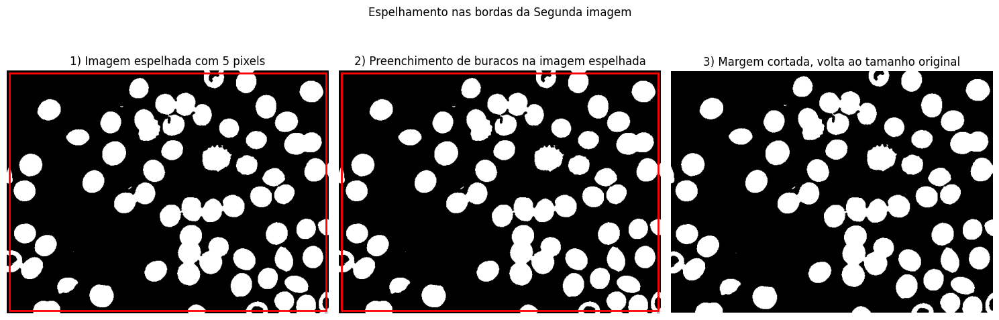

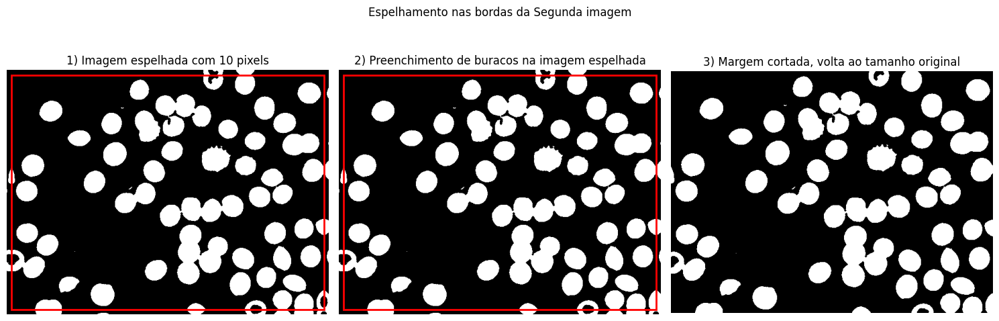

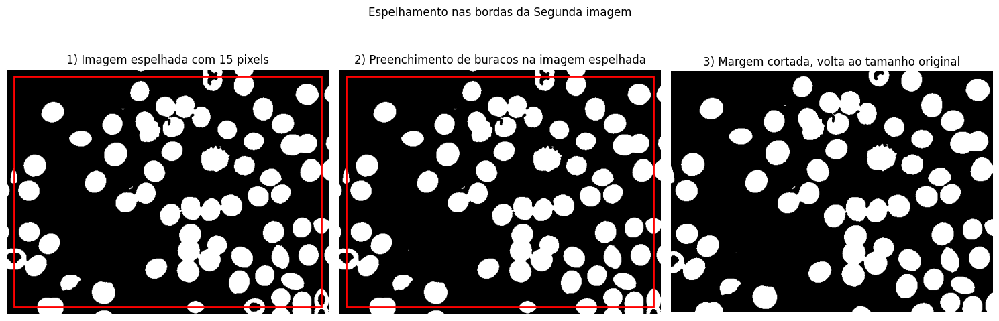

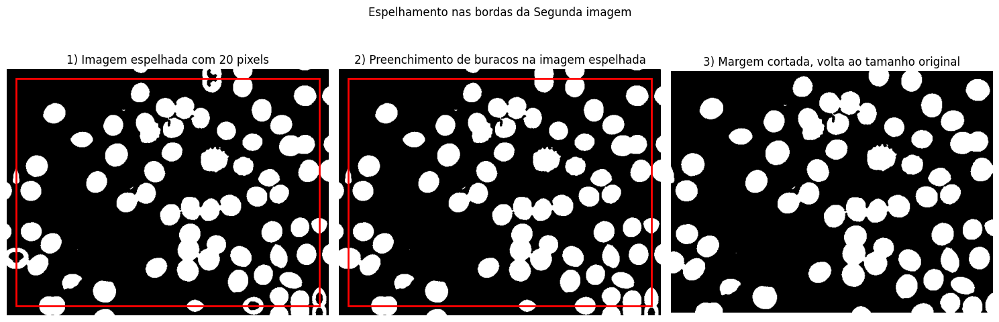

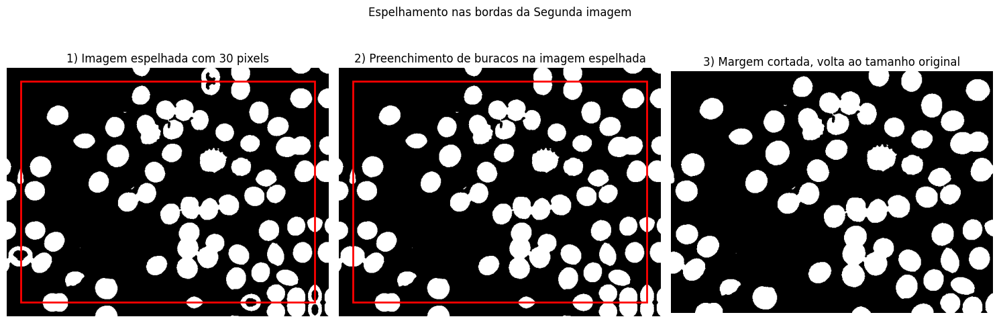

In [ ]:
for margem_testada in [5, 10, 15, 20, 30]:
        mostrar_teste_espelhamento(img2_preenchida, margem_testada, elemento_preenchimento, "Segunda imagem")


In [ ]:
# teste do tamanho da margem nas duas imagens

for nome, preenchida in [("Primeira imagem", img1_preenchida),("Segunda imagem", img2_preenchida)]:

    # resultado com uma margem muito grande (200 pixels), usado como referência
    referencia, _, _ = preencher_buracos_da_borda(preenchida, 200, elemento_preenchimento)

    for margem in [5, 10, 15, 20, 30, 60, 80]:
        teste, _, _ = preencher_buracos_da_borda(preenchida, margem, elemento_preenchimento)
        diferencas = np.count_nonzero(teste != referencia)
        print(f"{nome} | margem de {margem} pixels | "f"{diferencas} pixels diferentes da margem de 200")


Primeira imagem | margem de 5 pixels | 377 pixels diferentes da margem de 200
Primeira imagem | margem de 10 pixels | 377 pixels diferentes da margem de 200
Primeira imagem | margem de 15 pixels | 0 pixels diferentes da margem de 200
Primeira imagem | margem de 20 pixels | 0 pixels diferentes da margem de 200
Primeira imagem | margem de 30 pixels | 0 pixels diferentes da margem de 200
Primeira imagem | margem de 60 pixels | 0 pixels diferentes da margem de 200
Primeira imagem | margem de 80 pixels | 0 pixels diferentes da margem de 200
Segunda imagem | margem de 5 pixels | 784 pixels diferentes da margem de 200
Segunda imagem | margem de 10 pixels | 642 pixels diferentes da margem de 200
Segunda imagem | margem de 15 pixels | 466 pixels diferentes da margem de 200
Segunda imagem | margem de 20 pixels | 0 pixels diferentes da margem de 200
Segunda imagem | margem de 30 pixels | 0 pixels diferentes da margem de 200
Segunda imagem | margem de 60 pixels | 0 pixels diferentes da margem de 2

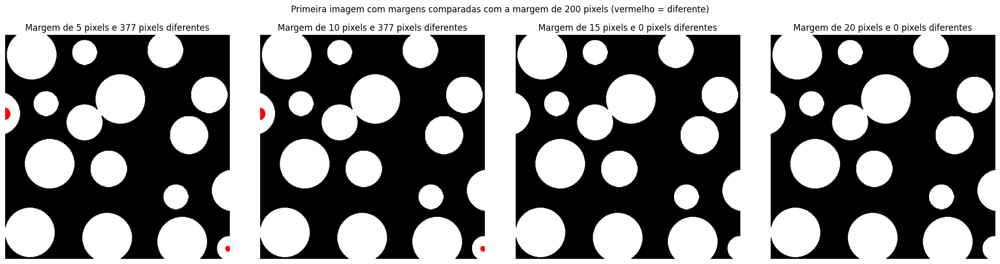

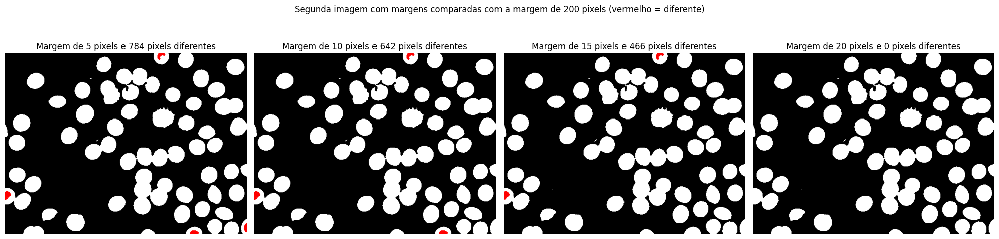

In [ ]:
# comparação das margens com a margem de 200
margens_figura = [5, 10, 15, 20]
diferencas_img1 = mostrar_comparacao_margens(img1_preenchida, margens_figura, elemento_preenchimento, "Primeira imagem")
diferencas_img2 = mostrar_comparacao_margens(img2_preenchida, margens_figura, elemento_preenchimento, "Segunda imagem")

Teste da margem:

- Comparamos cada margem com uma margem de 200 pixels, que serve só de referência por ser grande o bastante para fechar qualquer célula cortada. Nas figuras, o vermelho marca os pixels diferentes da referência, ou seja, buracos que não foram preenchidos.

- Primeira imagem: as margens de 5 e 10 pixels deixaram 377 pixels diferentes e de 15 em diante deu 0.
- Segunda imagem: a margem de 5 deixou 784, a de 10 deixou 642 e a de 15 deixou 466. De 20 em diante deu 0.

Por que escolheos 20 pixels como margem:
- É a menor margem que deu 0 pixels diferentes nas duas imagens, então usamos o mesmo valor nas duas. Em imagens com buracos maiores perto da borda a margem precisaria ser maior, cerca do dobro do raio do maior buraco.

##### Abertura para remover pequenas partículas ou ruído

A abertura é uma erosão seguida de uma dilatação com o mesmo elemento.
- A erosão apaga tudo que é menor que o elemento, como pontinhos brancos soltos e ruído.
- A dilatação devolve o tamanho do que sobrou.

Por isso ela remove as pequenas partículas e mantém as células, que são maiores.

Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação
Operação de Erosão
Operação de Erosão
Operação de Dilatação
Operação de Dilatação



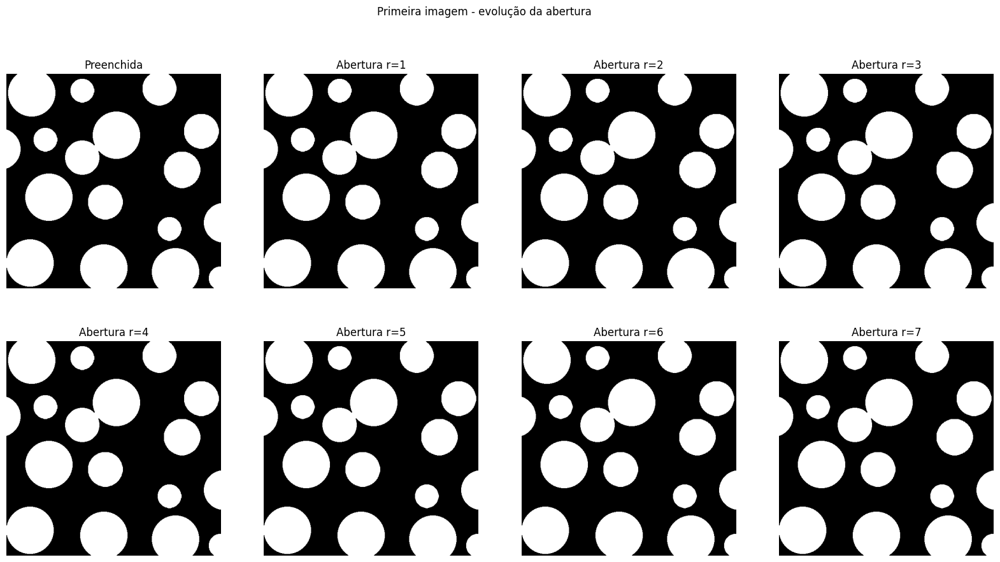

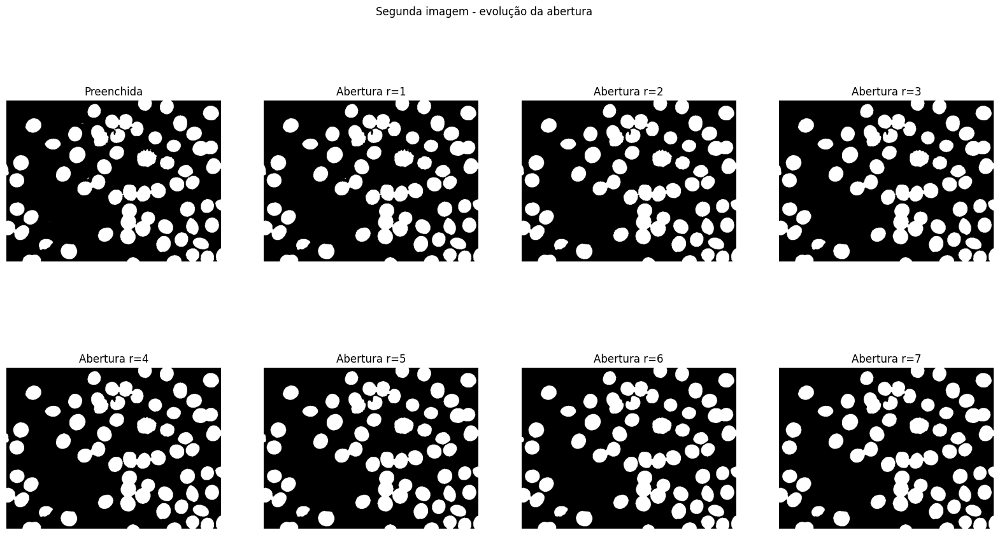


Primeira imagem com abertura testado com os raios [1, 2, 3, 4, 5, 6, 7], cada raio com 1 dilatação e 1 erosão (14 operações)
Segunda imagem com abertura testado com os raios [1, 2, 3, 4, 5, 6, 7], cada raio com 1 dilatação e 1 erosão (14 operações)


In [ ]:
# abertura
limpas_img1 = {}
limpas_img2 = {}

for r in raios_abertura:
    elemento = criar_elemento_circular(r)

    erodida_img1 = morf_dilate_erode(img1_preenchida_borda, elemento, padding=True, dilate=False) # erosão
    erodida_img2 = morf_dilate_erode(img2_preenchida_borda, elemento, padding=True, dilate=False)

    limpas_img1[r] = morf_dilate_erode(erodida_img1, elemento, padding=True, dilate=True) # dilatação (erosão + dilatação = abertura)
    limpas_img2[r] = morf_dilate_erode(erodida_img2, elemento, padding=True, dilate=True)

print()

mostrar_etapas([img1_preenchida_borda] + [limpas_img1[r] for r in raios_abertura], ["Preenchida"] + [f"Abertura r={r}" for r in raios_abertura], "Primeira imagem - evolução da abertura")
print()
mostrar_etapas([img2_preenchida_borda] + [limpas_img2[r] for r in raios_abertura], ["Preenchida"] + [f"Abertura r={r}" for r in raios_abertura], "Segunda imagem - evolução da abertura")

print()
for nome in ["Primeira imagem", "Segunda imagem"]:
    print(f"{nome} com abertura testado com os raios {raios_abertura}, cada raio com 1 dilatação e 1 erosão ({2 * len(raios_abertura)} operações)")

img1_limpa = limpas_img1[r_abertura_img1] # depois do gap-filling
img2_limpa = limpas_img2[r_abertura_img2]

- Raios testados: de 1 a 7, cada um com 1 erosão e 1 dilatação (14 operações por imagem).

- Raios escolhidos: 2 na primeira imagem (elemento 5x5) e 3 na segunda (elemento 7x7), aplicados uma vez em cada imagem.

<br>

Por que esses raios:

- Primeira imagem: não tem ruído, então a abertura quase não muda nada. Com os raios 1 e 2 nenhum pixel mudou, e do 3 ao 7 mudaram menos de 0,1% dos pixels brancos. Usamos o 2.
- Segunda imagem: antes da abertura sobravam 5 pedacinhos de 1 a 14 pixels, que são ruído. O raio 2 já remove todos. O raio 3 remove os mesmos e ainda desfaz uma ligação fina entre duas células. Com o raio 7 já some uma célula cortada na lateral esquerda. Por isso usamos o 3.

##### Imagens finais da questão 4:

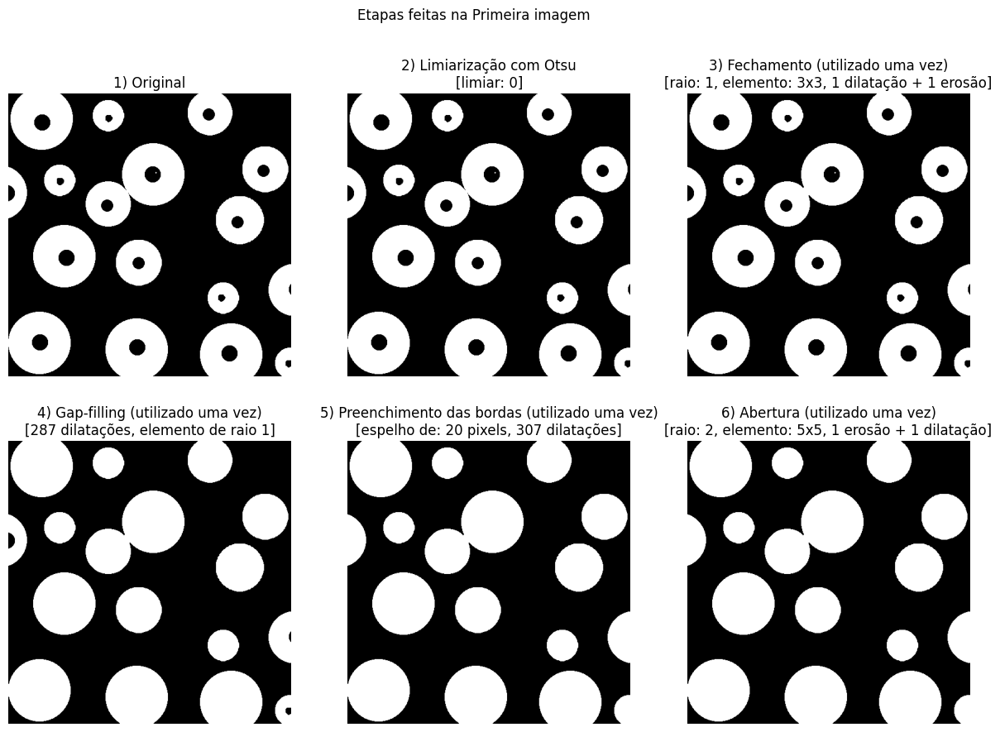

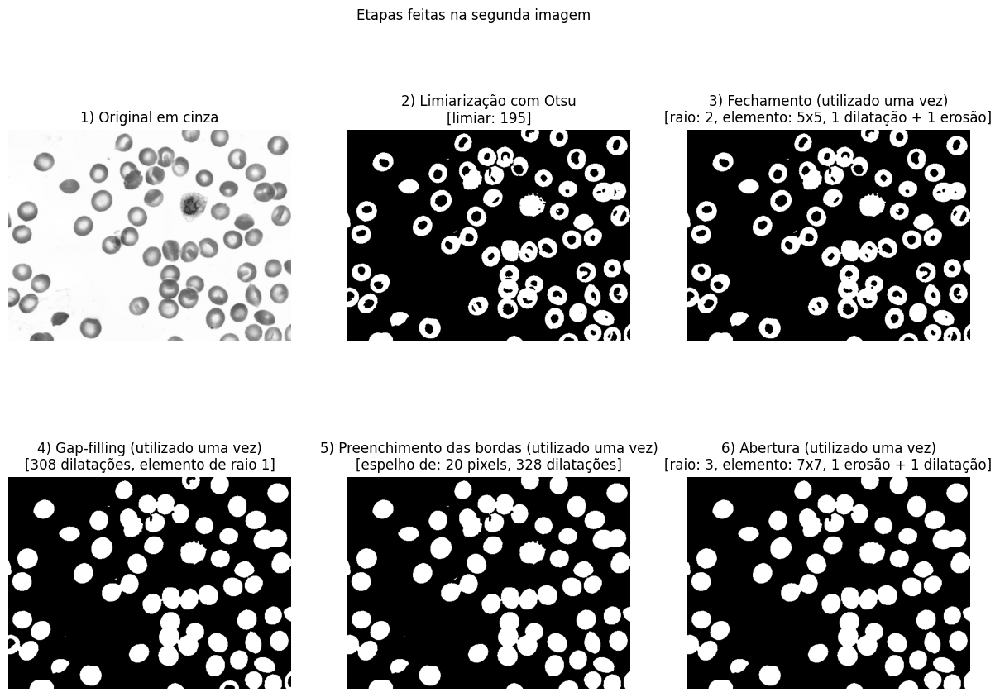

In [ ]:
# Etapas feitas na Primeira e Segudna imagem

mostrar_etapas([img1, img1_limiarizada, img1_fechada, img1_preenchida, img1_preenchida_borda, img1_limpa],
               ["1) Original",
                f"2) Limiarização com Otsu\n[limiar: {resultado_img1['limiar_otsu']}]",
                f"3) Fechamento (utilizado uma vez)\n[raio: {r_fechamento_img1}, elemento: {2 * r_fechamento_img1 + 1}x{2 * r_fechamento_img1 + 1}, 1 dilatação + 1 erosão]",
                f"4) Gap-filling (utilizado uma vez)\n[{dilatacoes1} dilatações, elemento de raio 1]",
                f"5) Preenchimento das bordas (utilizado uma vez)\n[espelho de: {margem_espelho} pixels, {dilatacoes1_borda} dilatações]",
                f"6) Abertura (utilizado uma vez)\n[raio: {r_abertura_img1}, elemento: {2 * r_abertura_img1 + 1}x{2 * r_abertura_img1 + 1}, 1 erosão + 1 dilatação]"],
               "Etapas feitas na Primeira imagem", colunas=3)


mostrar_etapas([img2, img2_limiarizada, img2_fechada, img2_preenchida, img2_preenchida_borda, img2_limpa],
               ["1) Original em cinza",
                f"2) Limiarização com Otsu\n[limiar: {resultado_img2['limiar_otsu']}]",
                f"3) Fechamento (utilizado uma vez)\n[raio: {r_fechamento_img2}, elemento: {2 * r_fechamento_img2 + 1}x{2 * r_fechamento_img2 + 1}, 1 dilatação + 1 erosão]",
                f"4) Gap-filling (utilizado uma vez)\n[{dilatacoes2} dilatações, elemento de raio 1]",
                f"5) Preenchimento das bordas (utilizado uma vez)\n[espelho de: {margem_espelho} pixels, {dilatacoes2_borda} dilatações]",
                f"6) Abertura (utilizado uma vez)\n[raio: {r_abertura_img2}, elemento: {2 * r_abertura_img2 + 1}x{2 * r_abertura_img2 + 1}, 1 erosão + 1 dilatação]"],
               "Etapas feitas na segunda imagem", colunas=3)

Resumo da questão 4:

Usamos um elemento circular (matriz de 2 x raio + 1) e testamos os raios de 1 a 7 no fechamento e na abertura. Cada etapa final foi aplicada uma vez em cada imagem.

<br>
Tabela com o resumo:

| Etapa |	Primeira imagem |	Segunda imagem |
| --- | --- | --- |
| Fechamento |	raio 1 (3x3), 1 dilatação + 1 erosão |	raio 2 (5x5), 1 dilatação + 1 erosão |
| Preenchimento de buracos | 287 dilatações (raio 1) | 308 dilatações (raio 1) |
| Preenchimento das bordas | espelho de 20 pixels, 307 dilatações | espelho de 20 pixels, 328 dilatações |
| Abertura |	raio 2 (5x5), 1 erosão + 1 dilatação | raio 3 (7x7), 1 erosão + 1 dilatação |

<br>

Os valores são diferentes porque as imagens são diferentes:
- A primeira é limpa e tem células grandes.
- A segunda tem células menores, mais ruído e células que se encostam.
- No fim, os buracos internos estão preenchidos (inclusive nas células cortadas pela borda) e o ruído foi removido.

### 5. Contagem de objetos (código próprio)

#### Implementar o seu próprio algoritmo de contagem de objetos automático.

##### Preparando para a contagem:

##### Contagem

In [48]:
def transformada_distancia(img):
    """
    Calcula a distância de cada pixel branco até a borda preta mais próxima
    em duas passadas (ida e volta). Bordas da imagem não contam como fundo.
    """
    altura, largura = img.shape
    dist = np.where(img == 255, 1e9, 0.0)

    # Passada de ida (cima -> baixo, esquerda -> direita)
    for i in range(altura):
        for j in range(largura):
            if dist[i, j] != 0:
                menor = dist[i, j]
                if i > 0:
                    menor = min(menor, dist[i - 1, j] + 1)
                if j > 0:
                    menor = min(menor, dist[i, j - 1] + 1)
                if i > 0 and j > 0:
                    menor = min(menor, dist[i - 1, j - 1] + 1.4142)
                if i > 0 and j < largura - 1:
                    menor = min(menor, dist[i - 1, j + 1] + 1.4142)
                dist[i, j] = menor

    # Passada de volta (baixo -> cima, direita -> esquerda)
    for i in range(altura - 1, -1, -1):
        for j in range(largura - 1, -1, -1):
            if dist[i, j] != 0:
                menor = dist[i, j]
                if i < altura - 1:
                    menor = min(menor, dist[i + 1, j] + 1)
                if j < largura - 1:
                    menor = min(menor, dist[i, j + 1] + 1)
                if i < altura - 1 and j < largura - 1:
                    menor = min(menor, dist[i + 1, j + 1] + 1.4142)
                if i < altura - 1 and j > 0:
                    menor = min(menor, dist[i + 1, j - 1] + 1.4142)
                dist[i, j] = menor

    return dist

def get_neighbors(i, j, h, w):
    """Vizinhança de 8 conexões do pixel (i, j), respeitando os limites da imagem."""
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            ni, nj = i + di, j + dj
            if 0 <= ni < h and 0 <= nj < w:
                yield ni, nj

def contar_por_miolos(img, h):
    """
    Conta e rotula as células a partir dos picos da transformada de distância.
    O parâmetro h define a proeminência mínima para considerar dois picos como células distintas.
    """
    altura, largura = img.shape
    dist = transformada_distancia(img)

    pixels = []
    for i in range(altura):
        for j in range(largura):
            if img[i, j] == 255:
                pixels.append((dist[i, j], i, j))
    pixels.sort(reverse=True)  # ordena do centro (maior distância) para a borda

    rotulos = np.zeros((altura, largura), dtype=np.int32)
    pai = [0]
    altura_pico = [0.0]

    def raiz(r):
        while pai[r] != r:
            pai[r] = pai[pai[r]]
            r = pai[r]
        return r

    for d, i, j in pixels:
        vizinhos = set()
        for ny, nx in get_neighbors(i, j, altura, largura):
            if rotulos[ny, nx] != 0:
                vizinhos.add(raiz(rotulos[ny, nx]))

        if len(vizinhos) == 0:
            # Novo pico local (centro de uma célula)
            pai.append(len(pai))
            altura_pico.append(d)
            rotulos[i, j] = len(pai) - 1
        else:
            # Herda o rótulo do pico mais alto entre os vizinhos
            principal = max(sorted(vizinhos), key=lambda r: altura_pico[r])
            rotulos[i, j] = principal

            # Une picos secundários se a diferença até o "pescoço" (d) for menor que h
            for outro in vizinhos:
                if outro != principal and altura_pico[outro] - d < h:
                    pai[outro] = principal

    # Renumera os rótulos finais sequencialmente de 1 até N
    novo = {}
    for i in range(altura):
        for j in range(largura):
            if rotulos[i, j] != 0:
                r = raiz(rotulos[i, j])
                if r not in novo:
                    novo[r] = len(novo) + 1
                rotulos[i, j] = novo[r]

    return rotulos, len(novo)

5.1 Algoritmo de Contagem

Para realizar a contagem o algoritmo foi dividido em duas etapas:

1. **Transformada de Distância (`transformada_distancia`):** Calcula, em duas passadas (ida e volta), a distância euclidiana aproximada de cada pixel branco até o fundo preto mais próximo, atribuindo peso $1$ para deslocamentos ortogonais e $\sqrt{2} \approx 1,4142$ para diagonais. As bordas externas da imagem não são tratadas como fundo para evitar distorções nas células cortadas pelo enquadramento. O resultado funciona como um mapa de relevo onde o centro ("miolo") de cada célula possui os maiores valores.
2. **Segmentação por Miolos (`contar_por_miolos`):** Ordena todos os pixels brancos do maior valor de distância para o menor, percorrendo cada célula do centro em direção às bordas. Sempre que um pixel não possui vizinhos já visitados, ele é registrado como o pico de uma nova célula. Conforme as regiões se expandem e se encontram nos pontos de contato ("pescoços" entre células vizinhas), uma estrutura *Union-Find* avalia a diferença entre a altura do pico secundário e a distância no ponto de encontro: caso essa diferença seja menor que o limiar $h$, os picos são fundidos por representarem apenas irregularidades de uma mesma célula; caso contrário, são mantidos como células distintas. Essa abordagem preserva o formato original dos objetos sem apagar células menores, como ocorreria em erosões sucessivas.

#### Comparar a contagem de células antes e depois do gap-filling.

Primeira imagem (contagem manual: 17)
    h | antes do gap-filling | depois do gap-filling
  0.5 |                   83 |                    17
    1 |                   45 |                    17
  1.5 |                   22 |                    17
    2 |                   21 |                    17
    3 |                   19 |                    17
    4 |                   19 |                    17
    5 |                   18 |                    17

Segunda imagem (contagem manual: 66)
    h | antes do gap-filling | depois do gap-filling
  0.5 |                  181 |                    67
    1 |                  117 |                    66
  1.5 |                   80 |                    64
    2 |                   75 |                    64
    3 |                   65 |                    64
    4 |                   62 |                    63
    5 |                   59 |                    63

Primeira imagem: 21 células antes do gap-filling x 17 depois (manual: 17)
S

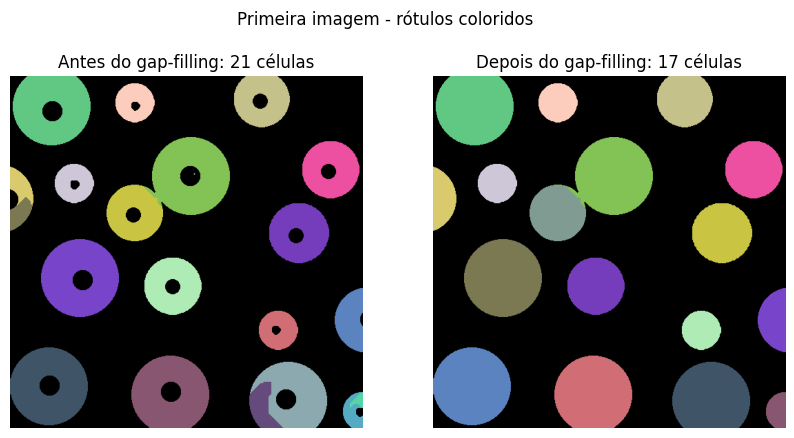

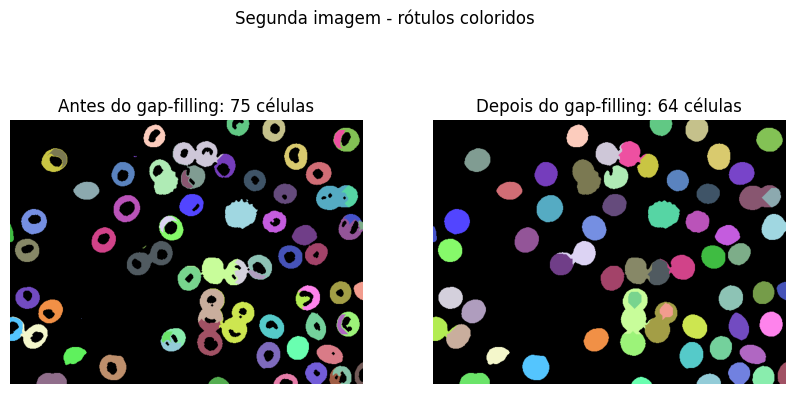

In [49]:
def colorir_rotulos(rotulos):
    """Atribui uma cor aleatória fixa para cada objeto rotulado (fundo preto)."""
    cores = np.zeros((rotulos.shape[0], rotulos.shape[1], 3), dtype=np.uint8)
    sorteio = np.random.RandomState(1)

    for r in range(1, rotulos.max() + 1):
        cores[rotulos == r] = sorteio.randint(60, 256, size=3)

    return cores


# Referência da contagem manual feita na Questão 3
contagem_manual = {"Primeira imagem": 17, "Segunda imagem": 66}

# 1. Teste de sensibilidade do parâmetro h (antes vs. depois do gap-filling)
valores_h = [0.5, 1, 1.5, 2, 3, 4, 5]

for nome, antes, depois in [("Primeira imagem", img1_fechada, img1_limpa), ("Segunda imagem", img2_fechada, img2_limpa)]:
    print(f"{nome} (contagem manual: {contagem_manual[nome]})")
    print(f"{'h':>5} | {'antes do gap-filling':>20} | {'depois do gap-filling':>21}")
    for h in valores_h:
        print(f"{h:>5} | {contar_por_miolos(antes, h)[1]:>20} | {contar_por_miolos(depois, h)[1]:>21}")
    print()

# 2. Contagem final usando o h escolhido no intervalo estável
h_img1, h_img2 = 2, 2

rot1_antes_m, n1_antes_m = contar_por_miolos(img1_fechada, h_img1)
rot1_depois_m, n1_depois_m = contar_por_miolos(img1_limpa, h_img1)
rot2_antes_m, n2_antes_m = contar_por_miolos(img2_fechada, h_img2)
rot2_depois_m, n2_depois_m = contar_por_miolos(img2_limpa, h_img2)

print(f"Primeira imagem: {n1_antes_m} células antes do gap-filling x {n1_depois_m} depois (manual: {contagem_manual['Primeira imagem']})")
print(f"Segunda imagem: {n2_antes_m} células antes do gap-filling x {n2_depois_m} depois (manual: {contagem_manual['Segunda imagem']})")

# 3. Visualização comparativa dos rótulos coloridos
mostrar_etapas(
    [colorir_rotulos(rot1_antes_m), colorir_rotulos(rot1_depois_m)],
    [f"Antes do gap-filling: {n1_antes_m} células", f"Depois do gap-filling: {n1_depois_m} células"],
    "Primeira imagem - rótulos coloridos",
    colunas=2
)
mostrar_etapas(
    [colorir_rotulos(rot2_antes_m), colorir_rotulos(rot2_depois_m)],
    [f"Antes do gap-filling: {n2_antes_m} células", f"Depois do gap-filling: {n2_depois_m} células"],
    "Segunda imagem - rótulos coloridos",
    colunas=2
)

#### 5.2 Comparação Antes e Depois do Gap-Filling

Nesta etapa, o algoritmo de contagem é aplicado sobre as imagens antes do preenchimento de buracos (`img1_fechada` e `img2_fechada`) e após a limpeza morfológica completa (`img1_limpa` e `img2_limpa`), utilizando a contagem manual da Questão 3 (17 células na primeira imagem e 66 na segunda) como referência:

* **Análise de sensibilidade do parâmetro $h$:** A tabela inicial testa diferentes valores de $h$ ($0,5$ a $5$) para identificar uma faixa de estabilidade onde ruídos de borda não gerem supersegmentação e células adjacentes não sejam unidas indevidamente. Com base nessa estabilização, adotou-se $h = 2$ para ambas as imagens.
* **Efeito do *gap-filling* na contagem:** Antes do preenchimento, as cavidades internas presentes nas células funcionam como regiões de fundo para a transformada de distância, criando múltiplos picos falsos ao redor dos anéis vazados e elevando artificialmente o total detectado. Após o *gap-filling*, o interior das células torna-se sólido e contínuo, fazendo com que cada célula apresente um único pico central bem definido e aproximando a contagem automática dos valores obtidos manualmente.
* **Visualização por rótulos coloridos (`colorir_rotulos`):** Cada componente identificado recebe uma cor distinta sobre o fundo preto, permitindo verificar visualmente que células próximas ou encostadas foram devidamente separadas e rotuladas individualmente no seu tamanho original.

### 6. Visualização e Resultados

* Apresentar imagens em:
  * I. Original
  * II. Após limiarização
  * III. Após morfologia
  * IV. Rótulos coloridos de cada célula

Gerando visualizações consolidadas para a Questão 6:


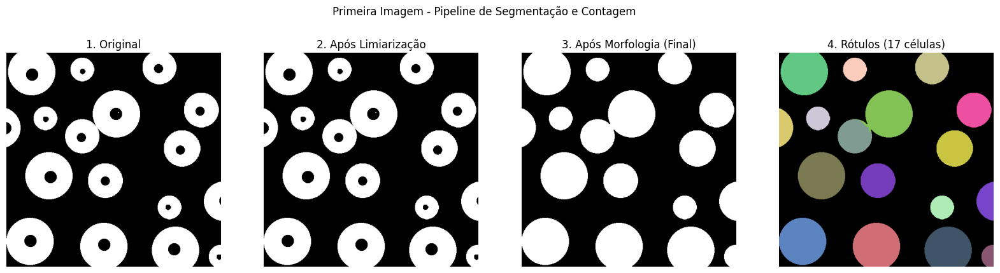

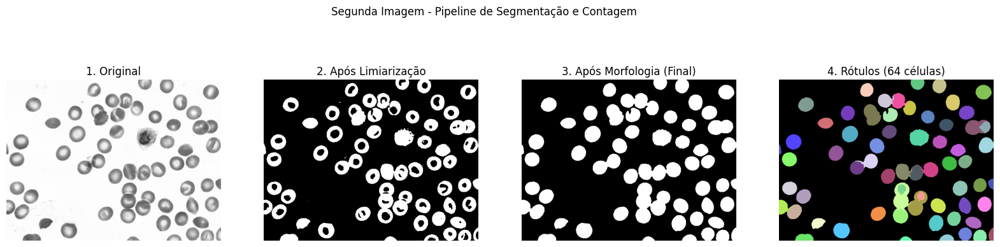

In [50]:
print("Gerando visualizações consolidadas para a Questão 6:")

# Primeira imagem
mostrar_etapas([img1, img1_limiarizada, img1_limpa, colorir_rotulos(rot1_depois_m)],["1. Original","2. Após Limiarização","3. Após Morfologia (Final)",f"4. Rótulos ({rot1_depois_m.max()} células)"],"Primeira Imagem - Pipeline de Segmentação e Contagem",colunas=4)

# Segunda imagem
mostrar_etapas([img2, img2_limiarizada, img2_limpa, colorir_rotulos(rot2_depois_m)],["1. Original","2. Após Limiarização","3. Após Morfologia (Final)",f"4. Rótulos ({rot2_depois_m.max()} células)"],"Segunda Imagem - Pipeline de Segmentação e Contagem",colunas=4)